# Original actor-feature FiLM: EE oscillation audit
Offline analysis of each checkpoint's own Exp2 recordings, primarily pushing/pulling. Selection requires recorded `film_v02_enabled=False`; V02 and non-FiLM recordings are excluded. No policy input perturbations, simulation, training, or model construction.
This tests **consistency with amplification**, not causality. Gait, estimator errors, trunk activity, base motion and actuator saturation remain alternative explanations.

In [3]:
from pathlib import Path
import json, os, sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'notebooks').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'notebooks'))
import exp3_film_oscillation as analysis
CONFIG = {
    # Figure typography in points; requires installed Times New Roman.
    "figure_title_font_size": 12,
    "title_font_size": 11,
    "axis_label_font_size": 10,
    "tick_font_size": 9,
    "legend_font_size": 9,
    "annotation_font_size": 8,
    'recording_roots': [str(ROOT / 'evaluation/exp2')],
    'tasks': ['b1z1_pact'],  # None discovers every compatible original-FiLM task.
    'checkpoints': None,  # Optional list of recorded SHA256 hashes.
    'checkpoint_paths': {},  # Optional {recorded_sha256: local_checkpoint_path}.
    'evaluation_seeds': [0, 1, 2],
    'profiles': ['pushing', 'pulling'],
    'loading': ['loaded', 'unloaded'],
    'trial_ids': None,  # e.g. [0, 1] for a small audit.
    'sustained_window_seconds': 4.0,
    'event_window_seconds': [-0.5, 2.0],
    'transient_margin_seconds': 0.25,
    'minimum_window_seconds': 1.25,  # Includes short loaded plateaus; not a low-frequency guarantee.
    'reference_stationarity_tolerance': 0.02,  # Max change in each native sphere coordinate.
    'nperseg': 64, 'overlap_fraction': 0.5, 'min_spectral_segments': 4,
    'segment_length_policy': 'adaptive', 'min_nperseg': 24,  # Or fixed; shorten only to retain >=4 averages.
    'minimum_cycles_per_window': 3,  # Frequencies below this or Welch resolution are unavailable.
    'moving_reference_mode': 'linear_detrended',  # Separate descriptive residual links; 'exclude' suppresses them.
    'temporal_ee_axis': 0, 'temporal_feature_index': 0,  # Fixed x / spherical radius and feature, not variance-selected.
    'temporal_joint_names': {},  # Optional {'arm': 'z1_shoulder', 'leg': 'FR_thigh_joint'}; default first named joint per group.
    'joint_groups': {},  # Optional exact recorded name lists; defaults z1_* (not gripper), FR_/FL_/RR_/RL_.
    'load_direction_min_n': 1., 'load_direction_tolerance_deg': 10.,
    'frequency_band_hz': [0.5, 12.0],  # None uses all positive Welch frequencies.
    'coherence_threshold': 0.6, 'max_lag_seconds': 0.5,
    'feature_epsilon': 1e-8,
    'head_parity_atol': 3e-5, 'head_parity_rtol': 3e-4,  # Strict CPU/GPU raw-action check; failures are reported, not hidden.
    'minimum_comparison_windows': 6, 'error_match_bin_m': 0.02,
    'pca': True, 'pca_samples': 1000, 'sampling_seed': 0,
    'pca_color': 'signed_error',  # Or load_stage / oscillation_phase (qualitative Hilbert phase).
    'tsne': False, 'tsne_perplexity': 30,  # Optional sklearn; qualitative only.
    'max_plot_windows': 12, 'max_windows': None,  # max_windows limits smoke runs only.
    'max_plot_relationships': 8,  # Figure-only cap, attributed links first; CSV keeps every link and named component.
    'output_dir': str(ROOT / 'analysis/exp3_film_oscillation'),
}
CONFIG.update(json.loads(os.environ.get('FILM_OSCILLATION_CONFIG', '{}')))


## Timing, coordinates, and spectral interpretation
Cartesian error is measured minus reference in the yaw-aligned task frame, in metres. Conditioning is command minus estimate: normalized body `[vx, vy, yaw_rate]` and spherical `[radius, elevation, azimuth]`. Measured conditioning is reconstructed at actor time **t**, using the recorded spherical/world reference pair to recover the workspace origin. Successor errors/motion remain at **t+1**.
Only contiguous valid pre-failure segments are analyzed, within each recorded load/motion stage. Short/failed windows are reported, not padded. Adaptive Hann Welch shortens segments to retain at least four overlapping averages (not four independent samples). Each window exports duration, segment count, resolution and usable frequency range; requested low frequencies below these limits are not interpreted. Stationary windows use constant detrending. Moving-reference tracking residuals and linked channels use linear detrending in a **separate nonstationary diagnostic**, never pooled with stationary results. Event windows retain descriptive spectra but no coherence. Lag peaks are exploratory: positive lag means the right signal follows the left; successor motion includes its +dt timestamp offset.
Temporal links use fixed signed axes/features and named joints across comparable windows, including FiLM-attributed position/FF changes to executed interval torques and successor motion. No maximum-variance component selection. Load-parallel/perpendicular errors use a stable mean world load direction and an exported orthonormal world basis; zero/varying load projections are unavailable. Arm/leg channel summaries use recorded joint names, excluding gripper joints, and retain per-joint PSDs in rad²/Hz or Nm²/Hz.
`gamma` is residual scaling: `post = (1+gamma)*pre + beta`. Temporal change is exactly `(1+gamma_previous)*delta_pre + delta_gamma*pre_current + delta_beta`. The last two terms form the parameter-change contribution. Their spectral powers are **not additive**, because cross terms remain.

In [4]:
result = analysis.run_analysis(CONFIG)
print(f"Analyzed {len(result['windows'])} windows from {len(result['provenance'])} recordings")
summary = pd.DataFrame(result['summary'])
if len(summary):
    metrics = ['ee_cartesian_error/oscillatory_rms', 'ee_cartesian_error/peak_to_peak', 'relative_modulation_rms', 'position_film/oscillatory_rms', 'torque_film/oscillatory_rms', 'parameter_change/band_power']
    display(summary[summary.metric.isin(metrics)])
display(pd.DataFrame(result['exclusions']))


FiLM analysis: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pulling/loaded/seed_0
FiLM analysis: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pulling/loaded/seed_1
FiLM analysis: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pulling/loaded/seed_2
FiLM analysis: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pushing/loaded/seed_0
FiLM analysis: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pushing/loaded/seed_1
FiLM analysis: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pushing/loaded/seed_2
Analyzed 3900 windows from 6 recordings


,task,checkpoint,training_seed,profile,loading,kind,stage,metric,analysis_mode,mean,std,count,variability
203,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pulling,loaded,load_change_response,4,ee_cartesian_error/oscillatory_rms,event_descriptive,0.016762,0.000127,3,evaluation-seed SD within checkpoint (not trai...
207,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pulling,loaded,load_change_response,4,ee_cartesian_error/peak_to_peak,event_descriptive,0.070944,0.000426,3,evaluation-seed SD within checkpoint (not trai...
1019,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pulling,loaded,load_change_response,4,parameter_change/band_power,event_descriptive,0.000079,0.000002,3,evaluation-seed SD within checkpoint (not trai...
1077,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pulling,loaded,load_change_response,4,relative_modulation_rms,event_descriptive,0.357184,0.000066,3,evaluation-seed SD within checkpoint (not trai...
1329,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pulling,loaded,load_change_response,5,ee_cartesian_error/oscillatory_rms,event_descriptive,0.011898,0.000051,3,evaluation-seed SD within checkpoint (not trai...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
28838,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pushing,loaded,sustained,7,relative_modulation_rms,stationary,0.311912,0.000086,3,evaluation-seed SD within checkpoint (not trai...
29111,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pushing,loaded,sustained,8,ee_cartesian_error/oscillatory_rms,stationary,0.012196,0.000125,3,evaluation-seed SD within checkpoint (not trai...
29115,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pushing,loaded,sustained,8,ee_cartesian_error/peak_to_peak,stationary,0.067814,0.002026,3,evaluation-seed SD within checkpoint (not trai...
29927,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,pushing,loaded,sustained,8,parameter_change/band_power,stationary,0.000041,0.000001,3,evaluation-seed SD within checkpoint (not trai...


,task,profile,loading,reason,checkpoint,training_seed,evaluation_seed,trial_id,run,kind,start,end,event,stage,motion_phase,load_stage,scheduled_load_n,window_id,analysis_mode
0,b1z1_pact,pushing,unloaded,"Missing compatible evaluation seeds: [0, 1, 2]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,b1z1_pact,pulling,unloaded,"Missing compatible evaluation seeds: [0, 1, 2]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,b1z1_pact,pulling,loaded,Exact head attribution unavailable: Linear hea...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,0.0,0.0,/home/oyoungquist/Research/Genesis_Development...,sustained,0.25,2.75,0.0,0.0,stationary,-1.0,0.0,0.0,stationary
3,b1z1_pact,pulling,loaded,Load projections unavailable: zero/missing/var...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,0.0,0.0,/home/oyoungquist/Research/Genesis_Development...,sustained,0.25,2.75,0.0,0.0,stationary,-1.0,0.0,0.0,stationary
4,b1z1_pact,pulling,loaded,Exact head attribution unavailable: Linear hea...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,0.0,1.0,/home/oyoungquist/Research/Genesis_Development...,sustained,0.25,2.75,0.0,0.0,stationary,-1.0,0.0,1.0,stationary
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8997,b1z1_pact,pushing,loaded,Load projections unavailable: zero/missing/var...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,2.0,47.0,/home/oyoungquist/Research/Genesis_Development...,sustained,23.25,27.25,23.0,8.0,stationary,3.0,0.0,3897.0,stationary
8998,b1z1_pact,pushing,loaded,Exact head attribution unavailable: Linear hea...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,2.0,48.0,/home/oyoungquist/Research/Genesis_Development...,sustained,23.25,27.25,23.0,8.0,stationary,3.0,0.0,3898.0,stationary
8999,b1z1_pact,pushing,loaded,Load projections unavailable: zero/missing/var...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,2.0,48.0,/home/oyoungquist/Research/Genesis_Development...,sustained,23.25,27.25,23.0,8.0,stationary,3.0,0.0,3898.0,stationary
9000,b1z1_pact,pushing,loaded,Exact head attribution unavailable: Linear hea...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,NaN,2.0,49.0,/home/oyoungquist/Research/Genesis_Development...,sustained,23.25,27.25,23.0,8.0,stationary,3.0,0.0,3899.0,stationary


## Recorded feature/action associations
Figures show deterministically selected windows, covering task, load/stage, sustained/event type, checkpoint/seed and lower/higher measured oscillatory RMS within comparable conditions. Selection prefers different trials; the budget may leave categories omitted, explicitly exported. It is not a representative random population sample. Tables average windows within trials, then trials within evaluation seeds, then evaluation seeds within each checkpoint; overlapping windows are not independent replicates. Stationary and moving-reference modes remain separate. Sample SD is undefined for one seed. Checkpoints stay separate; evaluation seeds are not independent training runs.
Linear-head attribution requires a matching checkpoint hash and reconstruction of recorded deterministic actions. CPU/GPU arithmetic may differ; the configured tolerances and maximum mismatch are reported, and strict failures retain feature-only results. Do not raise tolerances without investigating. Physical command effects are in rad/Nm before command clipping. Nominal torque effects, when mechanics are available, apply clipping and measured-state PD algebra; they ignore action delay/substeps and are **not executed torque or simulated counterfactuals**. Recorded executed interval means are labeled separately.
High/low comparisons are stratified by checkpoint/profile/load/motion stage, with explicit error-magnitude bins. PCA uses one centered pooled pre/post basis per checkpoint with paired points; explained variance is exported. t-SNE is disabled by default and cannot establish feedback amplification.

,run,profile,loading,evaluation_seed,kind,start,end,event,stage,motion_phase,...,trials,spectral_windows,temporal_windows,attribution_windows,reason,min_duration_seconds,min_segments,max_usable_low_hz,min_usable_high_hz,max_resolution_hz
0,/home/oyoungquist/Research/Genesis_Development...,pulling,loaded,0,sustained,0.25,2.75,0.0,0,stationary,...,50,50,50,0,Exact head attribution unavailable: Linear hea...,2.48,4,1.209677,12.0,1.020408
1,/home/oyoungquist/Research/Genesis_Development...,pulling,loaded,0,sustained,3.75,7.75,3.5,2,moving,...,50,50,50,0,Exact head attribution unavailable: Linear hea...,3.98,5,0.781250,12.0,0.781250
2,/home/oyoungquist/Research/Genesis_Development...,pulling,loaded,0,sustained,8.25,12.25,8.0,3,moving,...,50,50,50,0,Exact head attribution unavailable: Linear hea...,3.98,5,0.781250,12.0,0.781250
3,/home/oyoungquist/Research/Genesis_Development...,pulling,loaded,0,sustained,13.25,17.25,13.0,4,moving,...,50,50,50,0,Exact head attribution unavailable: Linear hea...,3.98,5,0.781250,12.0,0.781250
4,/home/oyoungquist/Research/Genesis_Development...,pulling,loaded,0,sustained,18.25,19.75,18.0,5,moving,...,50,50,50,0,Exact head attribution unavailable: Linear hea...,1.48,4,2.027027,12.0,1.724138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,/home/oyoungquist/Research/Genesis_Development...,pushing,loaded,2,load_change_response,12.50,15.00,13.0,4,moving,...,50,50,0,0,Exact head attribution unavailable: Linear hea...,2.48,4,1.209677,12.0,1.020408
74,/home/oyoungquist/Research/Genesis_Development...,pushing,loaded,2,load_change_response,17.50,20.00,18.0,5,moving,...,50,50,0,0,Exact head attribution unavailable: Linear hea...,2.48,4,1.209677,12.0,1.020408
75,/home/oyoungquist/Research/Genesis_Development...,pushing,loaded,2,load_removal_response,22.50,25.00,23.0,8,stationary,...,50,50,0,0,Exact head attribution unavailable: Linear hea...,2.48,4,1.209677,12.0,1.020408
76,/home/oyoungquist/Research/Genesis_Development...,pushing,loaded,2,motion_response,2.50,5.00,3.0,1,moving,...,50,50,0,0,Exact head attribution unavailable: Linear hea...,2.48,4,1.209677,12.0,1.020408


,category,value,reason
0,stage,"('pulling', 'loaded', 'load_change_response', ...",plot budget/available-trial coverage
1,stage,"('pulling', 'loaded', 'load_change_response', ...",plot budget/available-trial coverage
2,stage,"('pulling', 'loaded', 'load_change_response', ...",plot budget/available-trial coverage
3,stage,"('pulling', 'loaded', 'load_onset_response', 3...",plot budget/available-trial coverage
4,stage,"('pulling', 'loaded', 'load_removal_response',...",plot budget/available-trial coverage
5,stage,"('pulling', 'loaded', 'load_removal_response',...",plot budget/available-trial coverage
6,stage,"('pulling', 'loaded', 'motion_response', 1, 'h...",plot budget/available-trial coverage
7,stage,"('pulling', 'loaded', 'motion_response', 1, 'l...",plot budget/available-trial coverage
8,stage,"('pulling', 'loaded', 'stop_response', 6, 'high')",plot budget/available-trial coverage
9,stage,"('pulling', 'loaded', 'stop_response', 6, 'low')",plot budget/available-trial coverage


{'profile': 'pushing', 'loading': 'loaded', 'stage': 5, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 2, 'trial_id': 26, 'actual_start': 17.5, 'actual_end': 20.0, 'severity_group': 'high'}


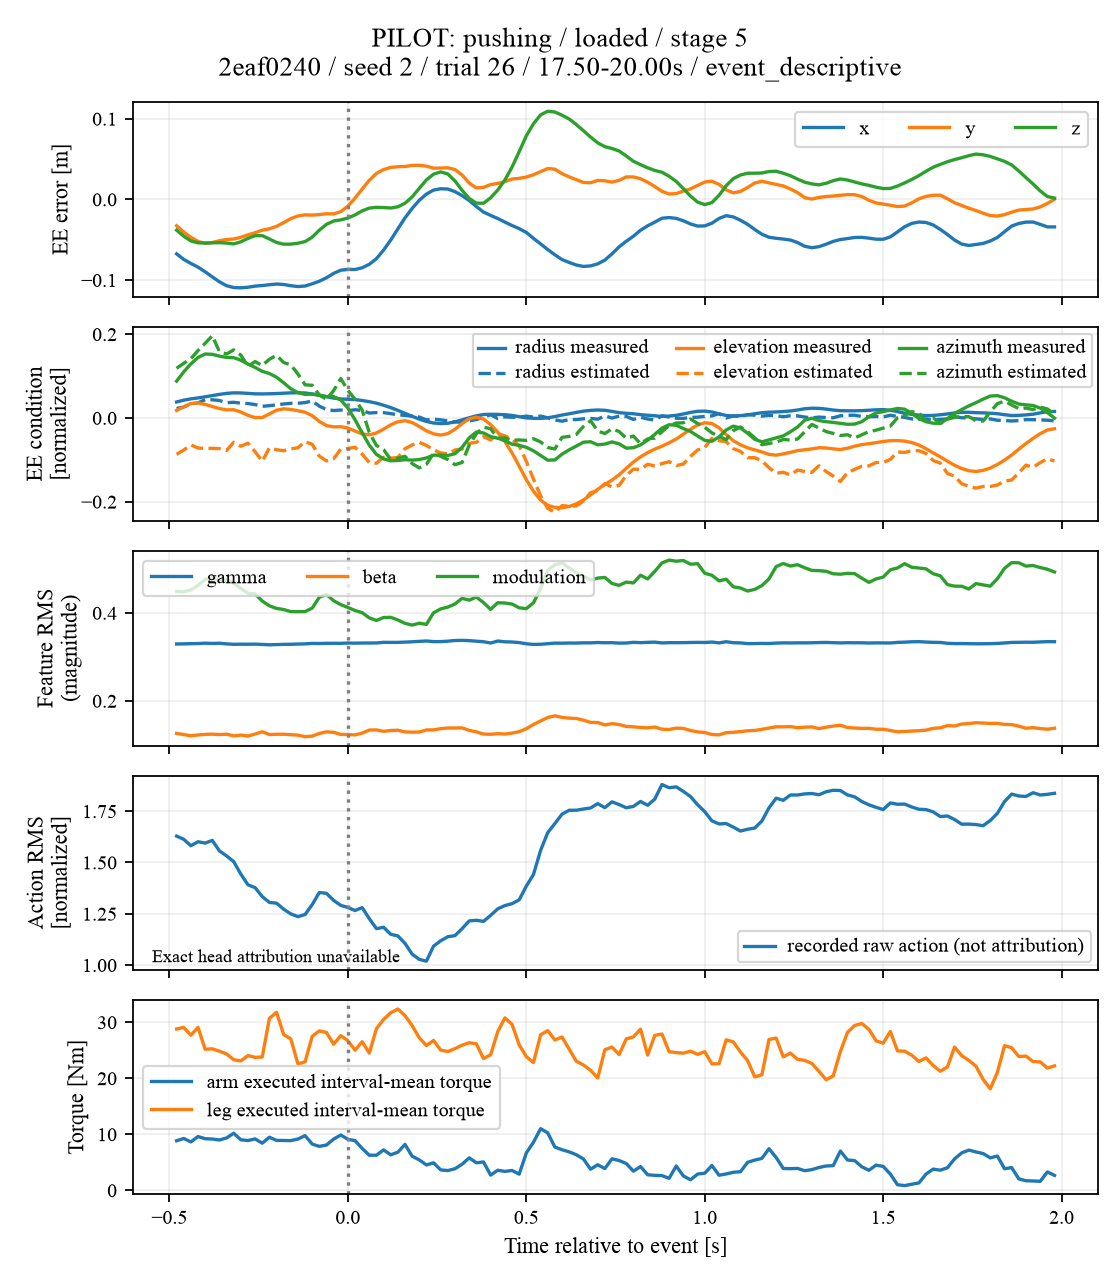

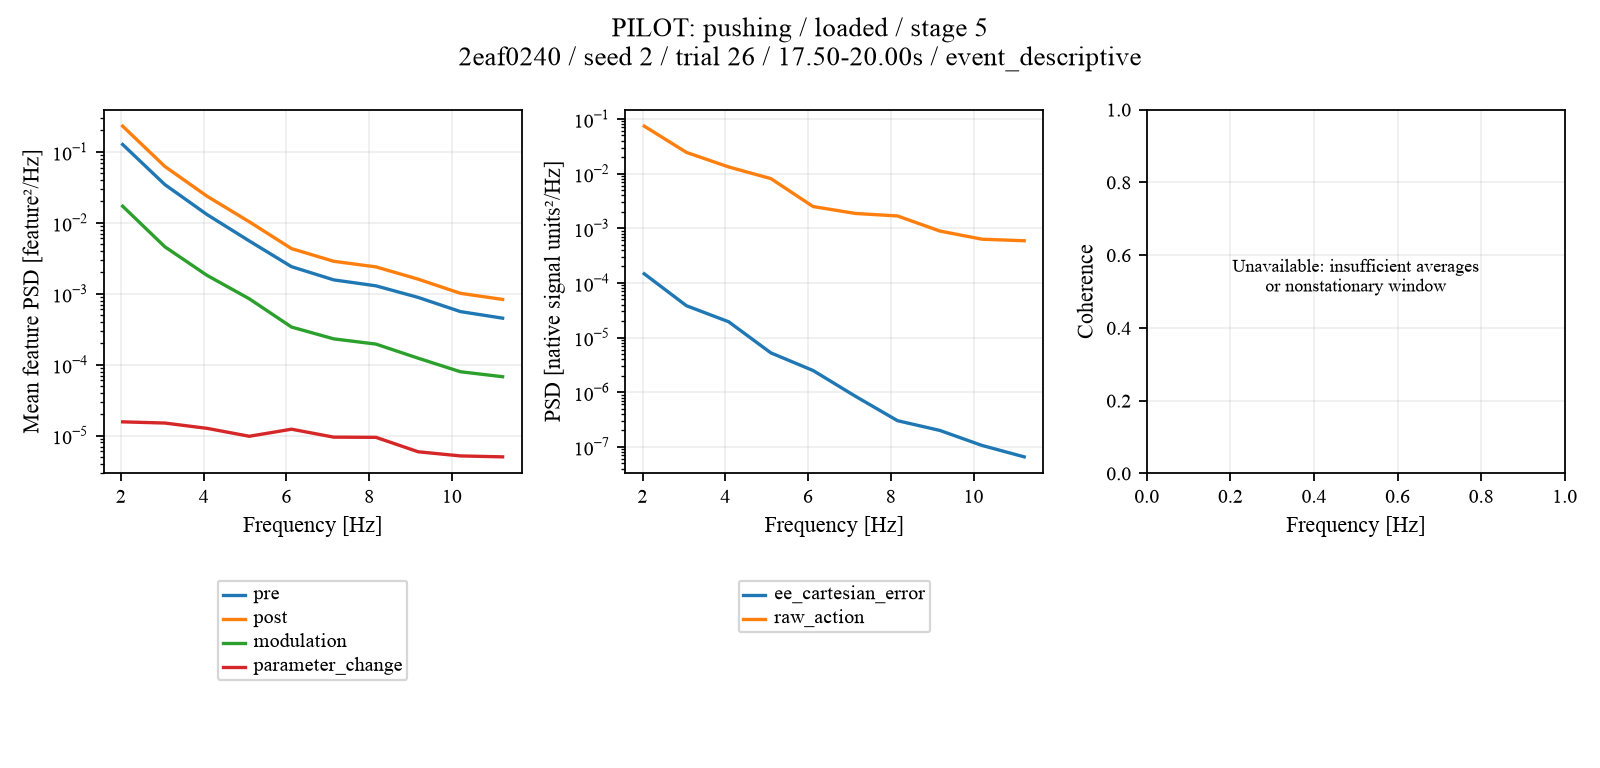

{'profile': 'pulling', 'loading': 'loaded', 'stage': 8, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 1, 'trial_id': 2, 'actual_start': 23.26, 'actual_end': 27.26, 'severity_group': 'low'}


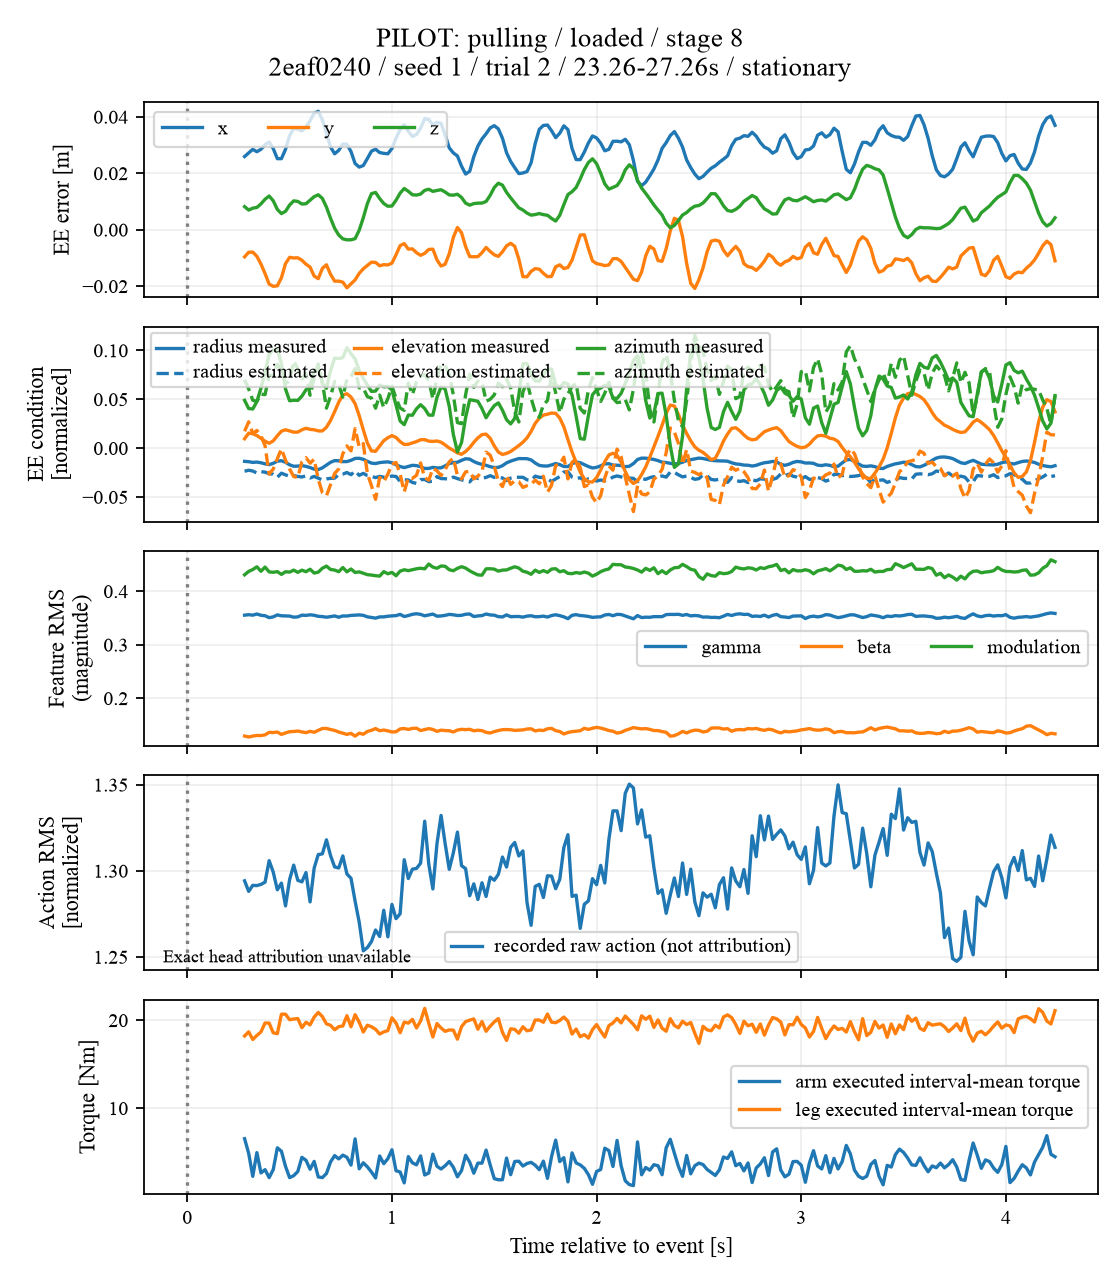

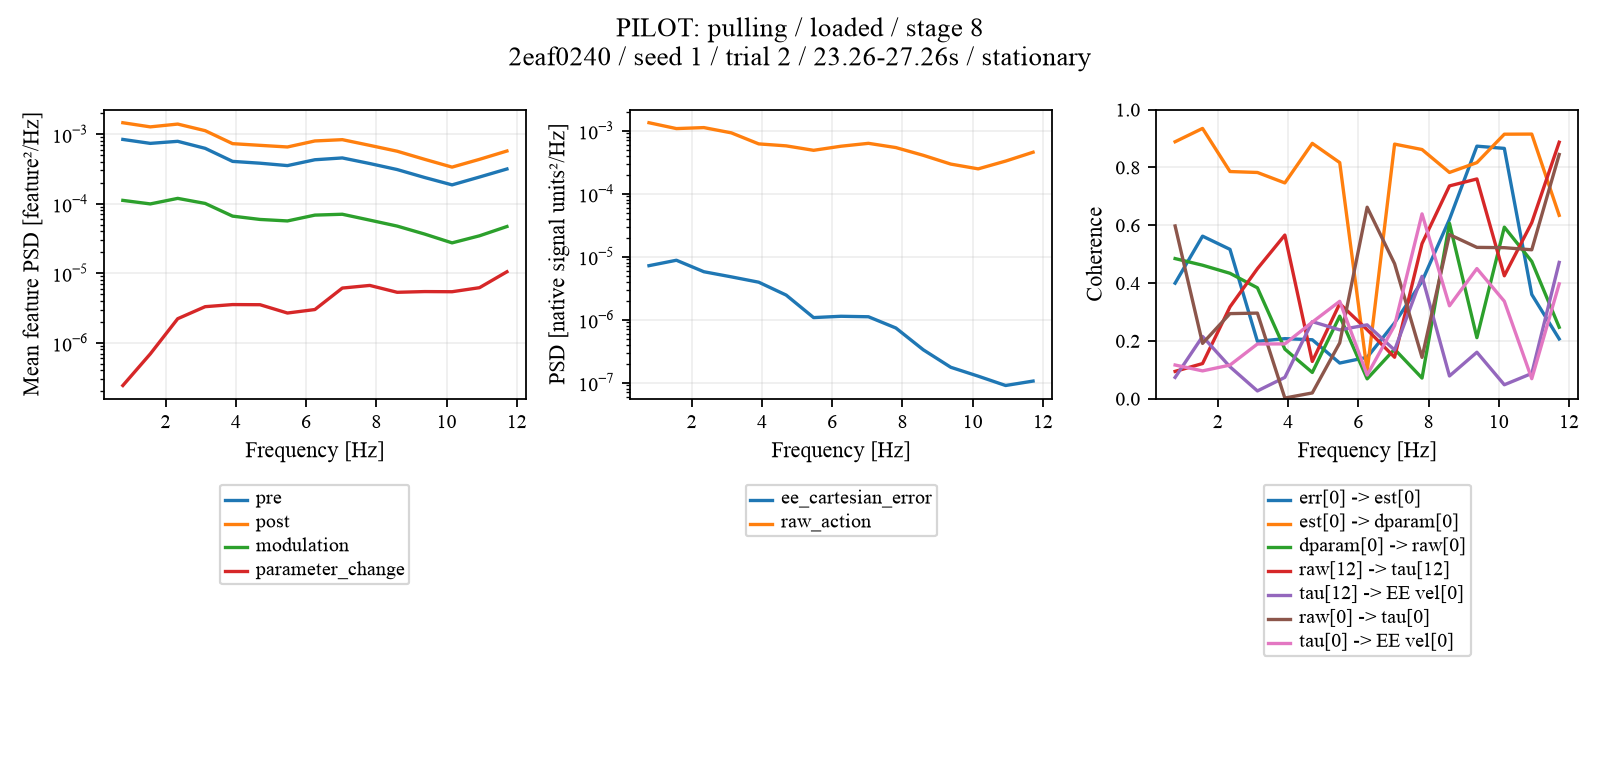

{'profile': 'pushing', 'loading': 'loaded', 'stage': 5, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 0, 'trial_id': 11, 'actual_start': 18.26, 'actual_end': 19.76, 'severity_group': 'high'}


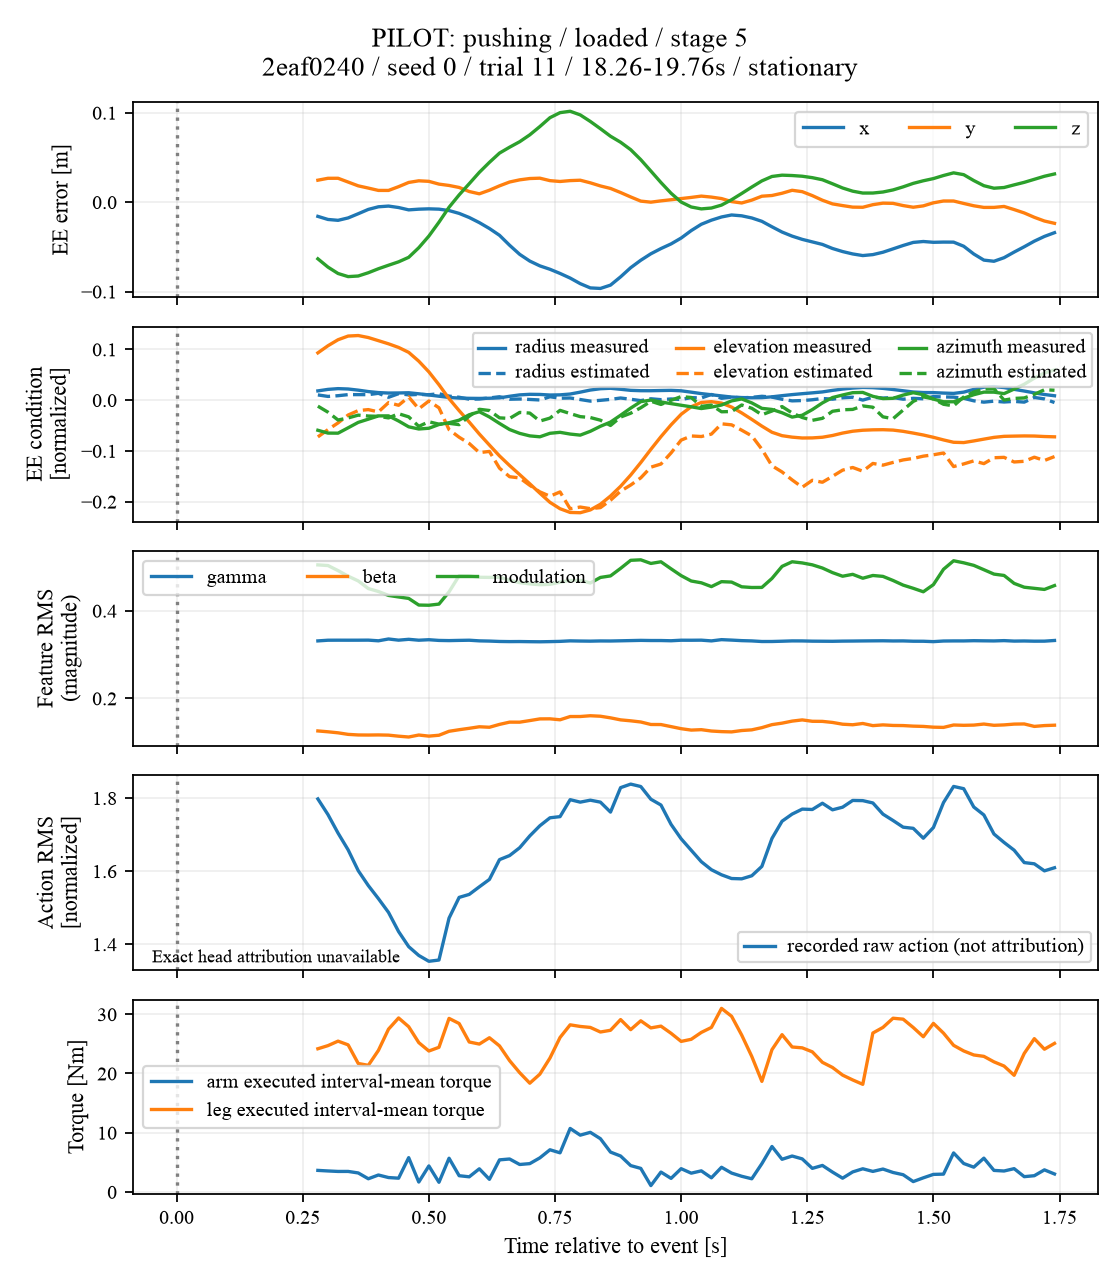

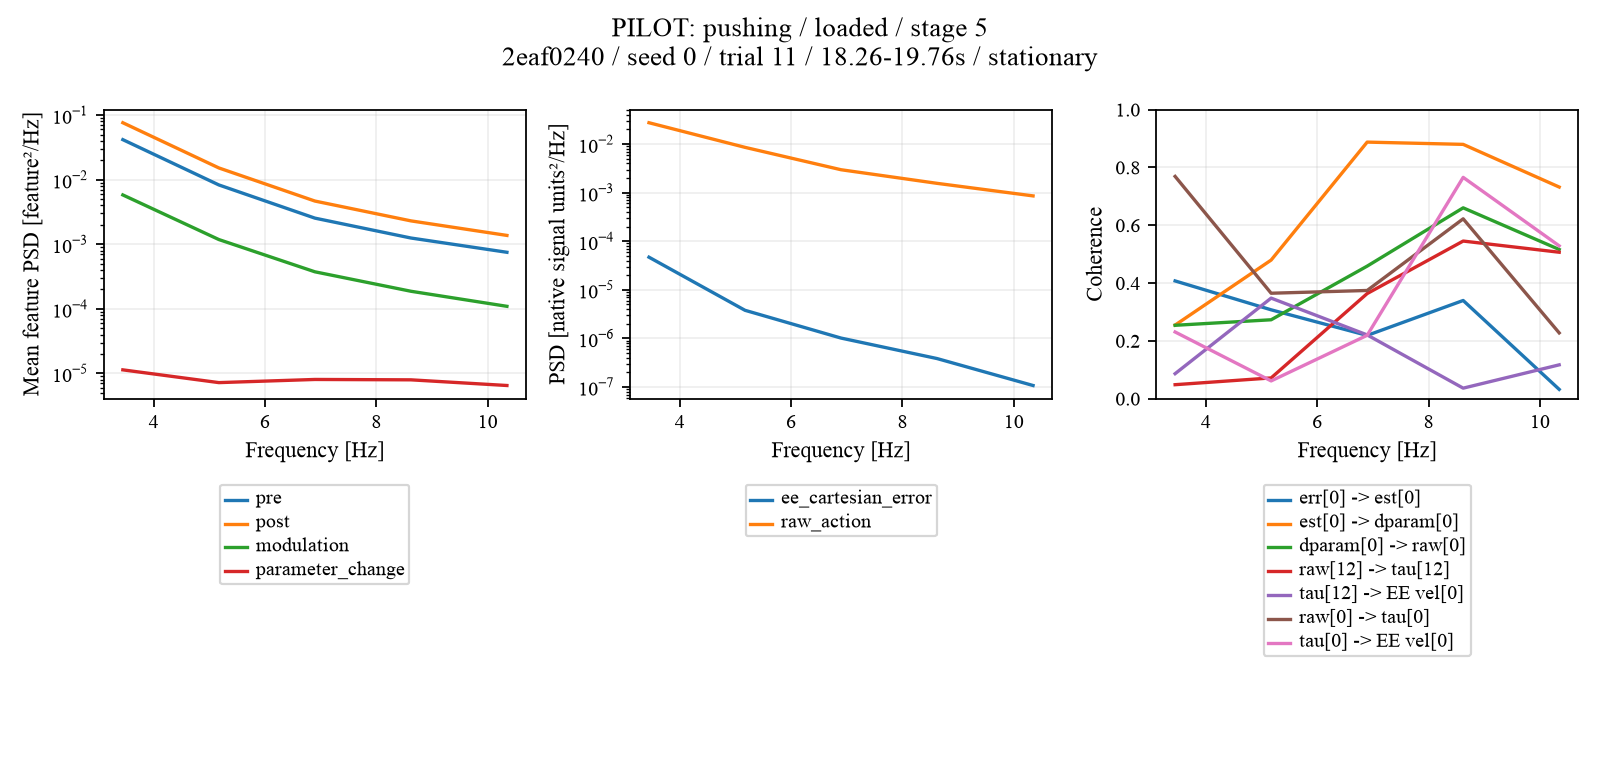

{'profile': 'pushing', 'loading': 'loaded', 'stage': 8, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 0, 'trial_id': 12, 'actual_start': 22.5, 'actual_end': 25.0, 'severity_group': 'high'}


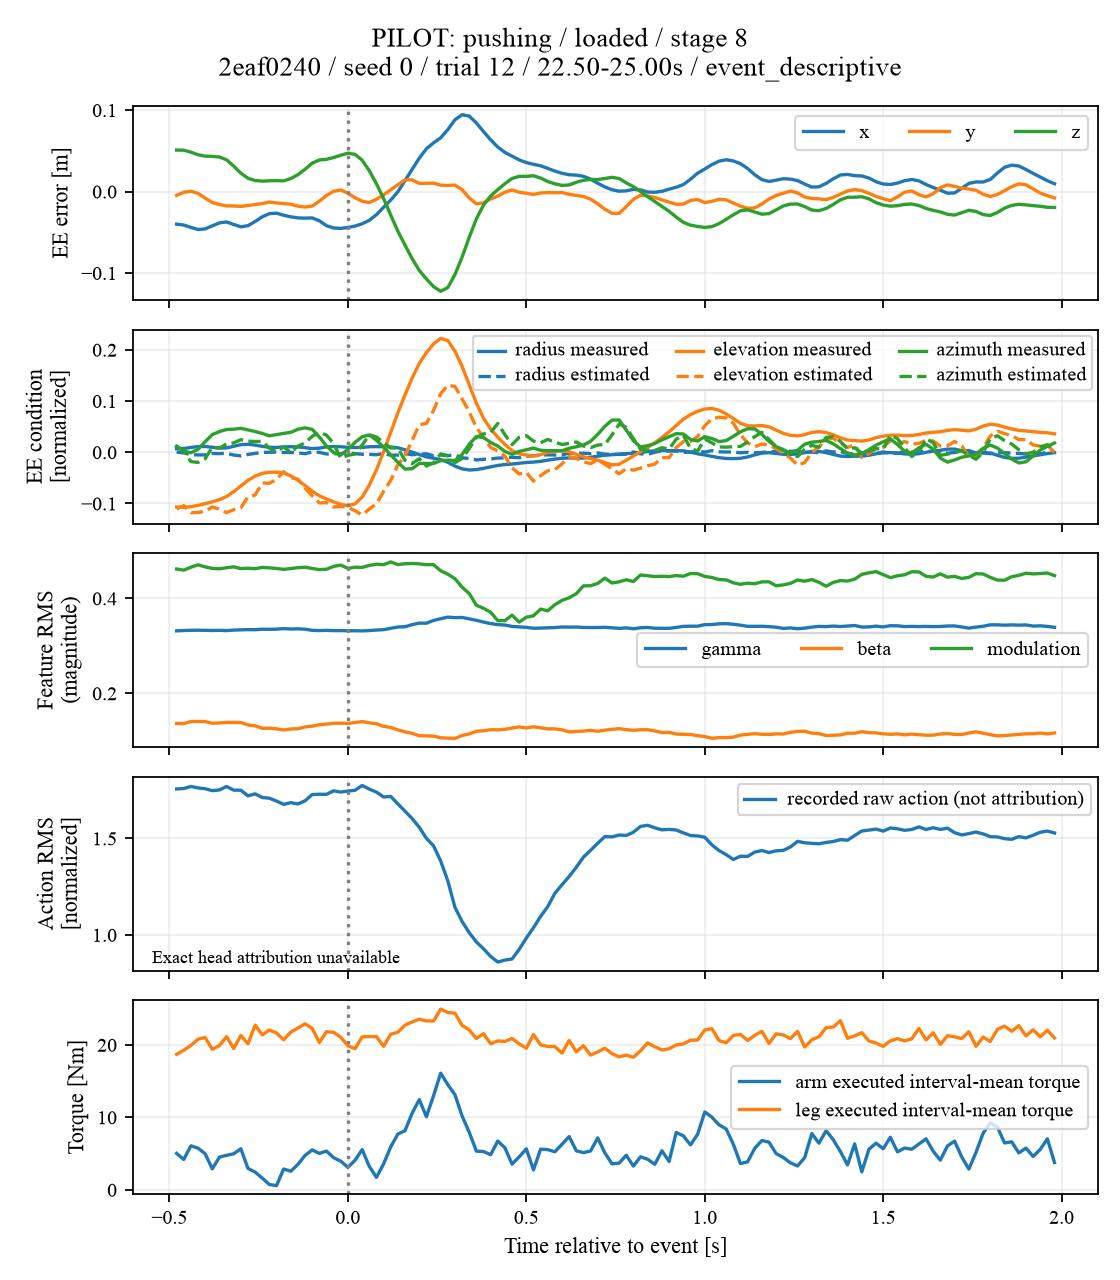

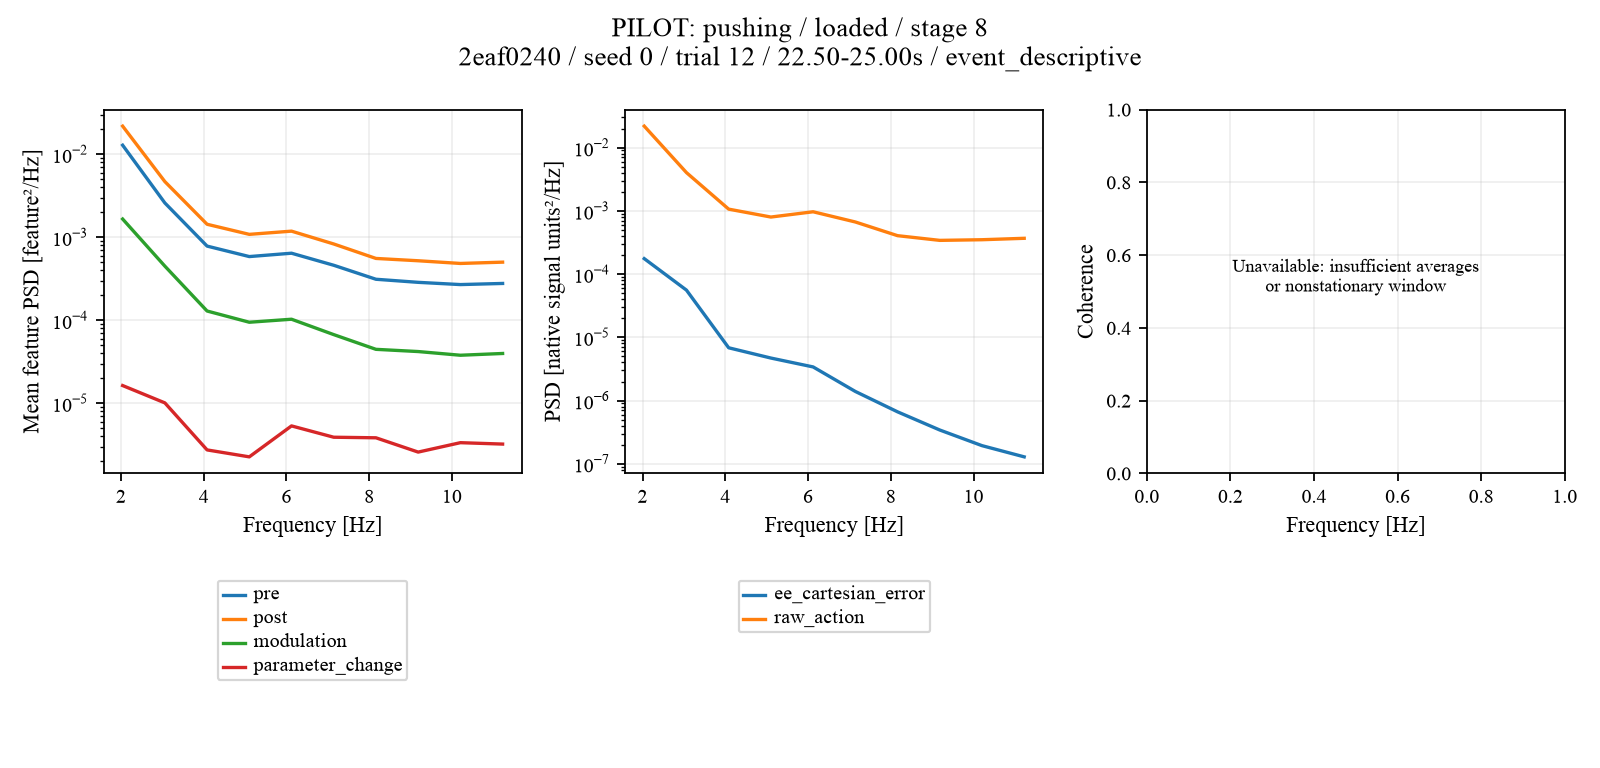

{'profile': 'pushing', 'loading': 'loaded', 'stage': 4, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 1, 'trial_id': 45, 'actual_start': 13.26, 'actual_end': 17.26, 'severity_group': 'high'}


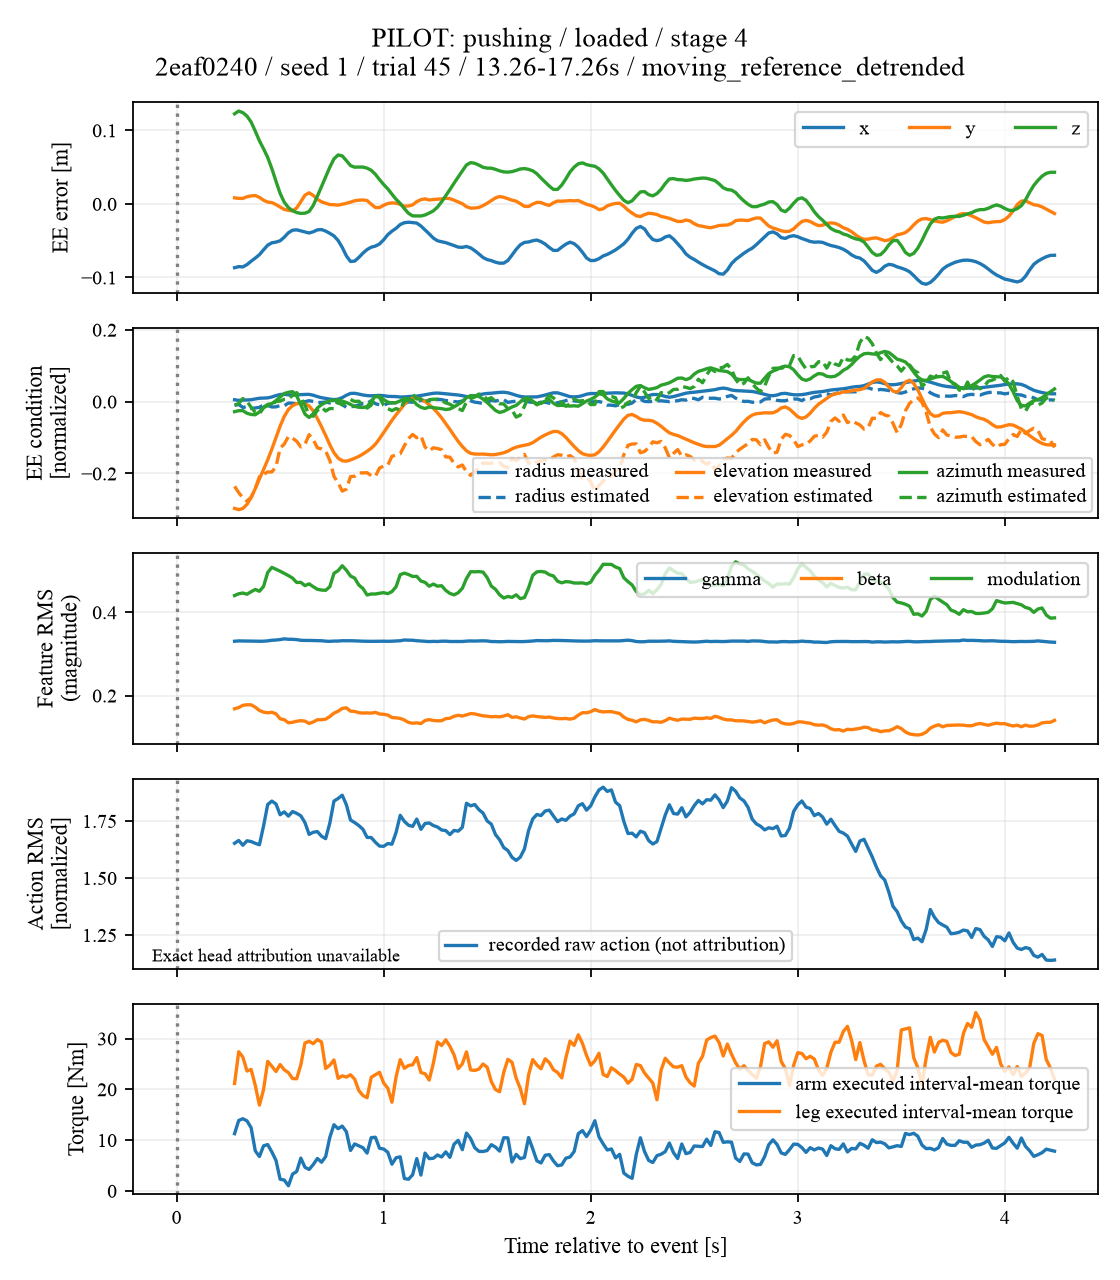

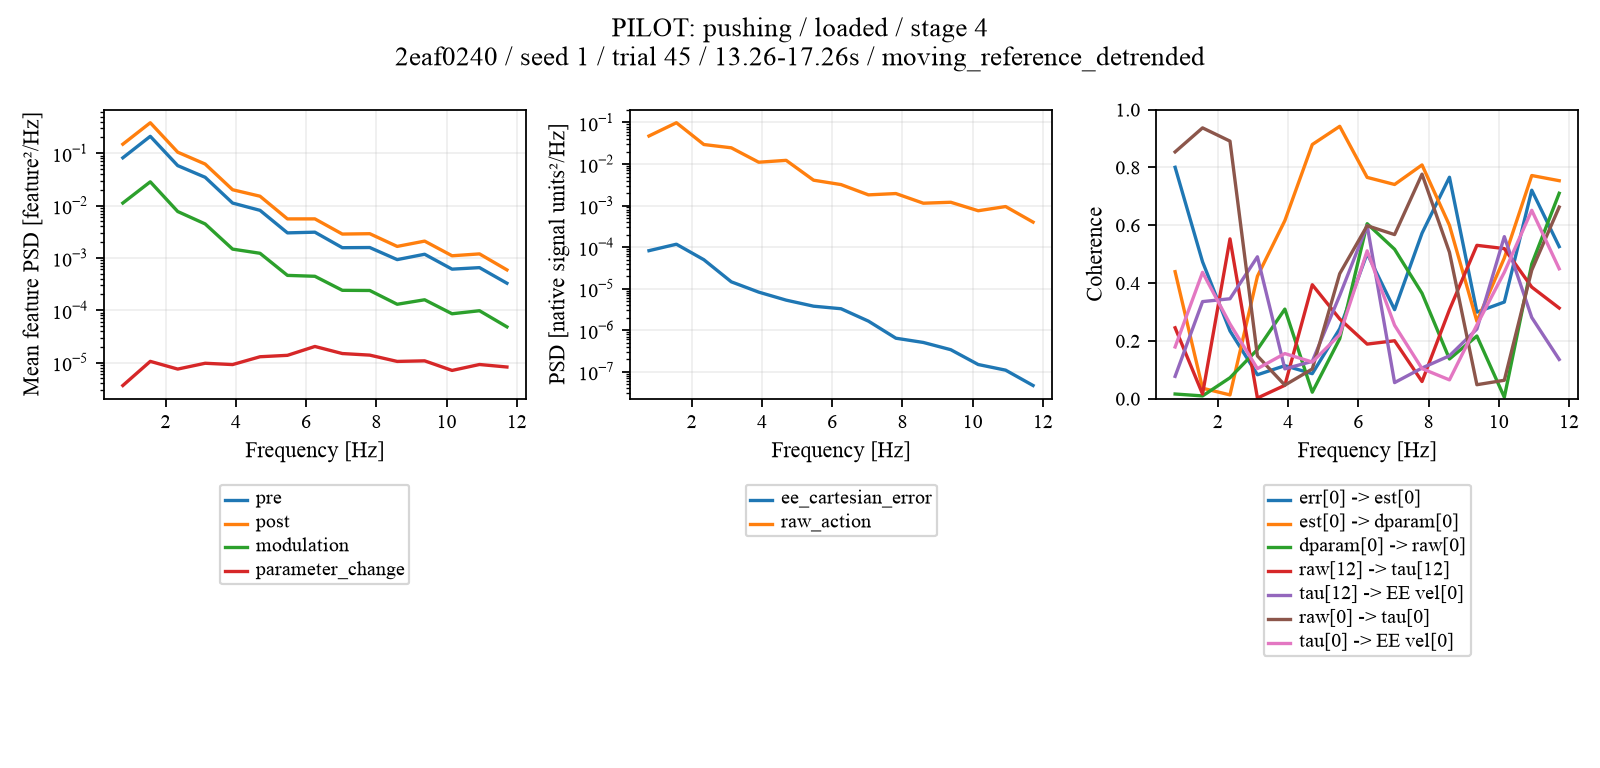

{'profile': 'pushing', 'loading': 'loaded', 'stage': 4, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 1, 'trial_id': 23, 'actual_start': 12.5, 'actual_end': 15.0, 'severity_group': 'high'}


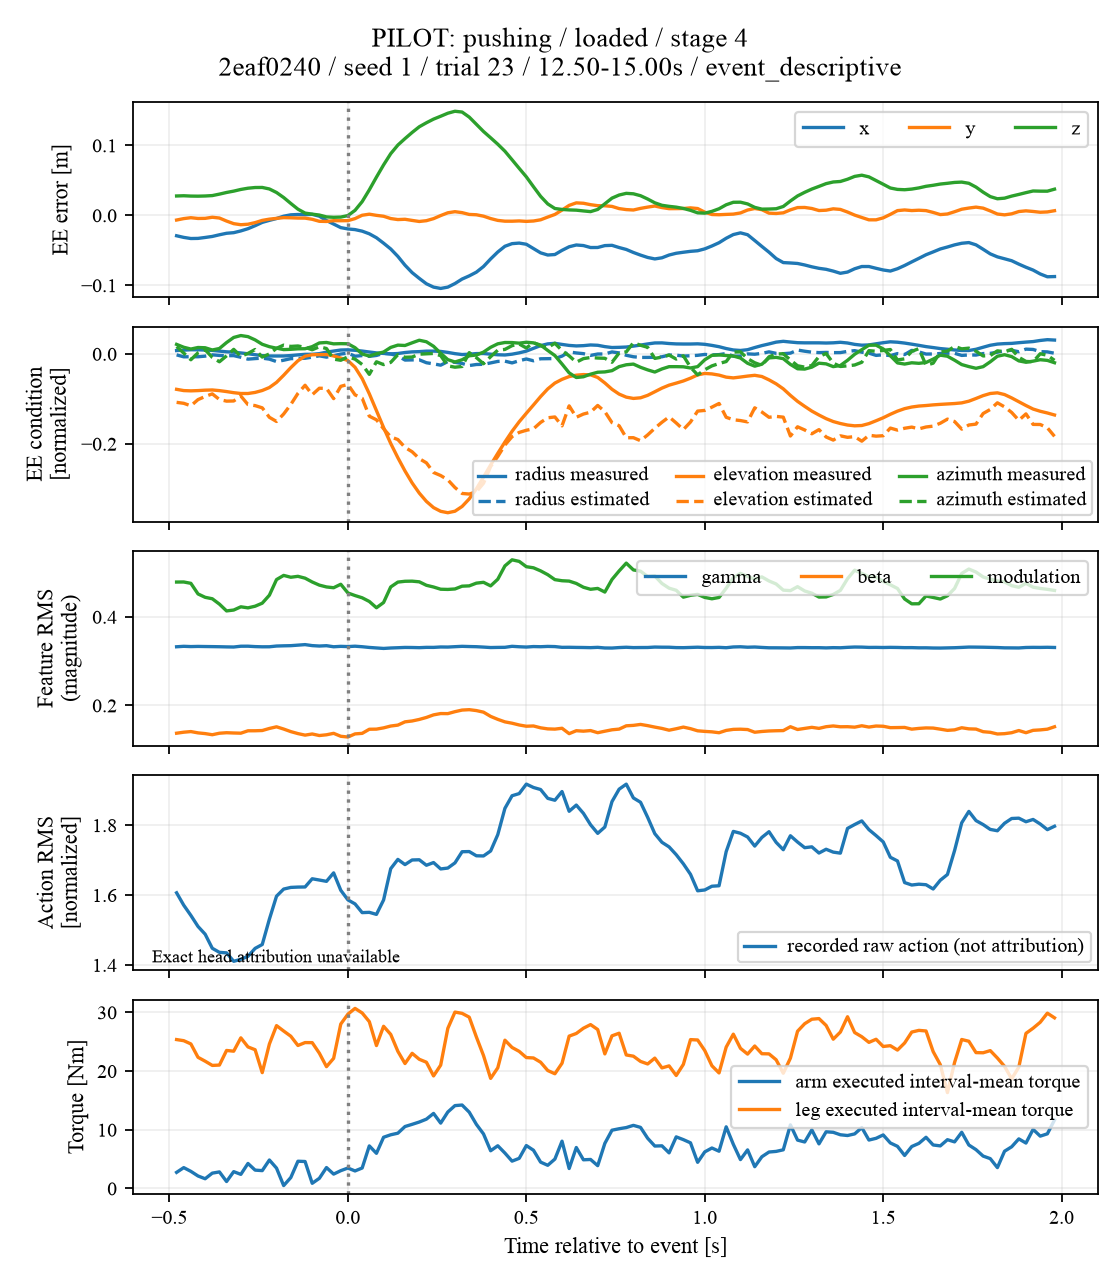

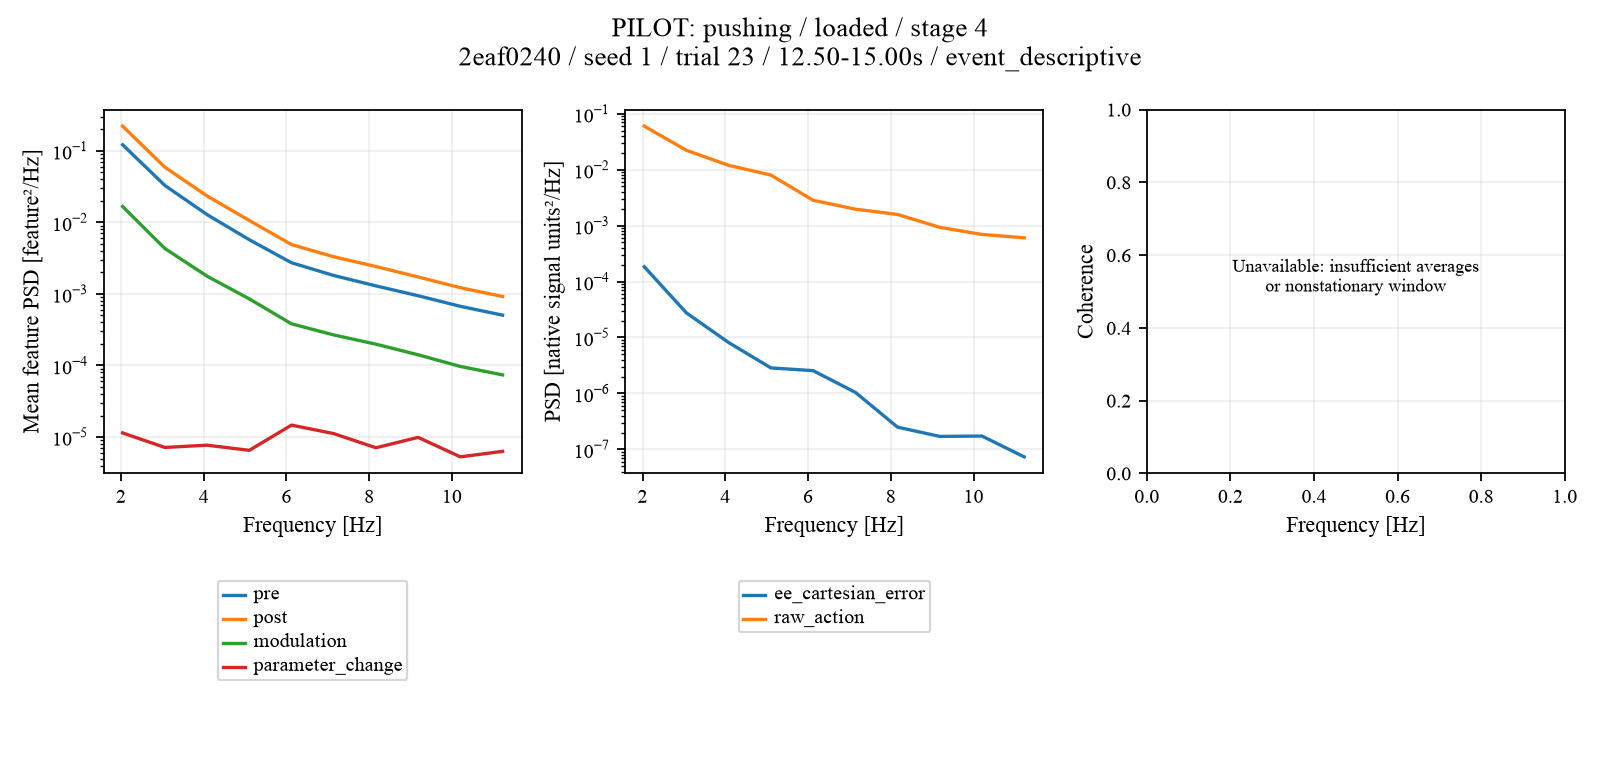

{'profile': 'pulling', 'loading': 'loaded', 'stage': 4, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 1, 'trial_id': 31, 'actual_start': 12.5, 'actual_end': 15.0, 'severity_group': 'high'}


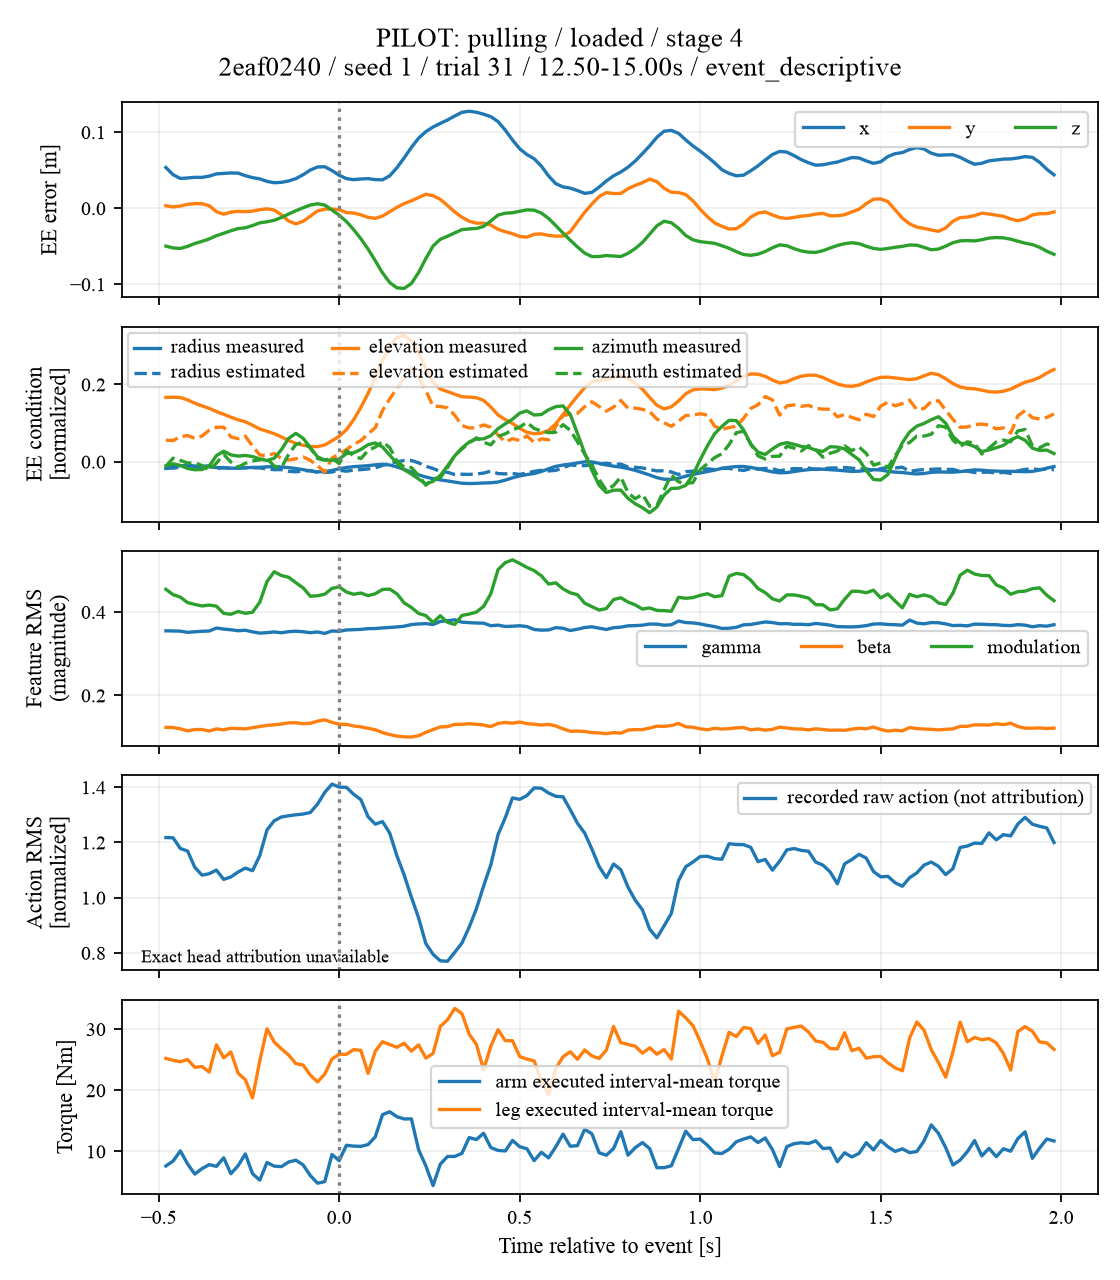

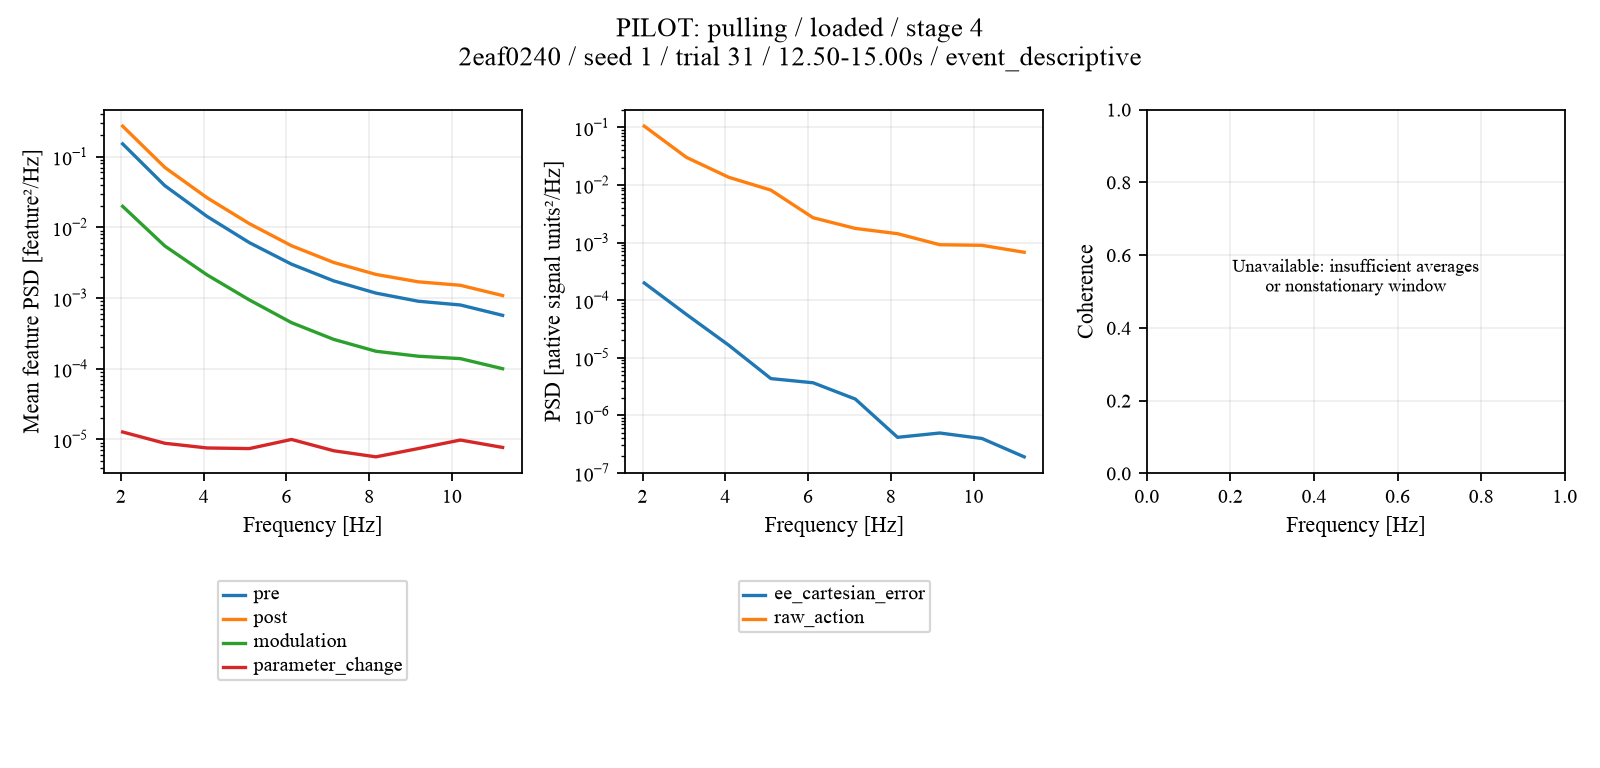

{'profile': 'pushing', 'loading': 'loaded', 'stage': 6, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 2, 'trial_id': 48, 'actual_start': 19.5, 'actual_end': 22.0, 'severity_group': 'high'}


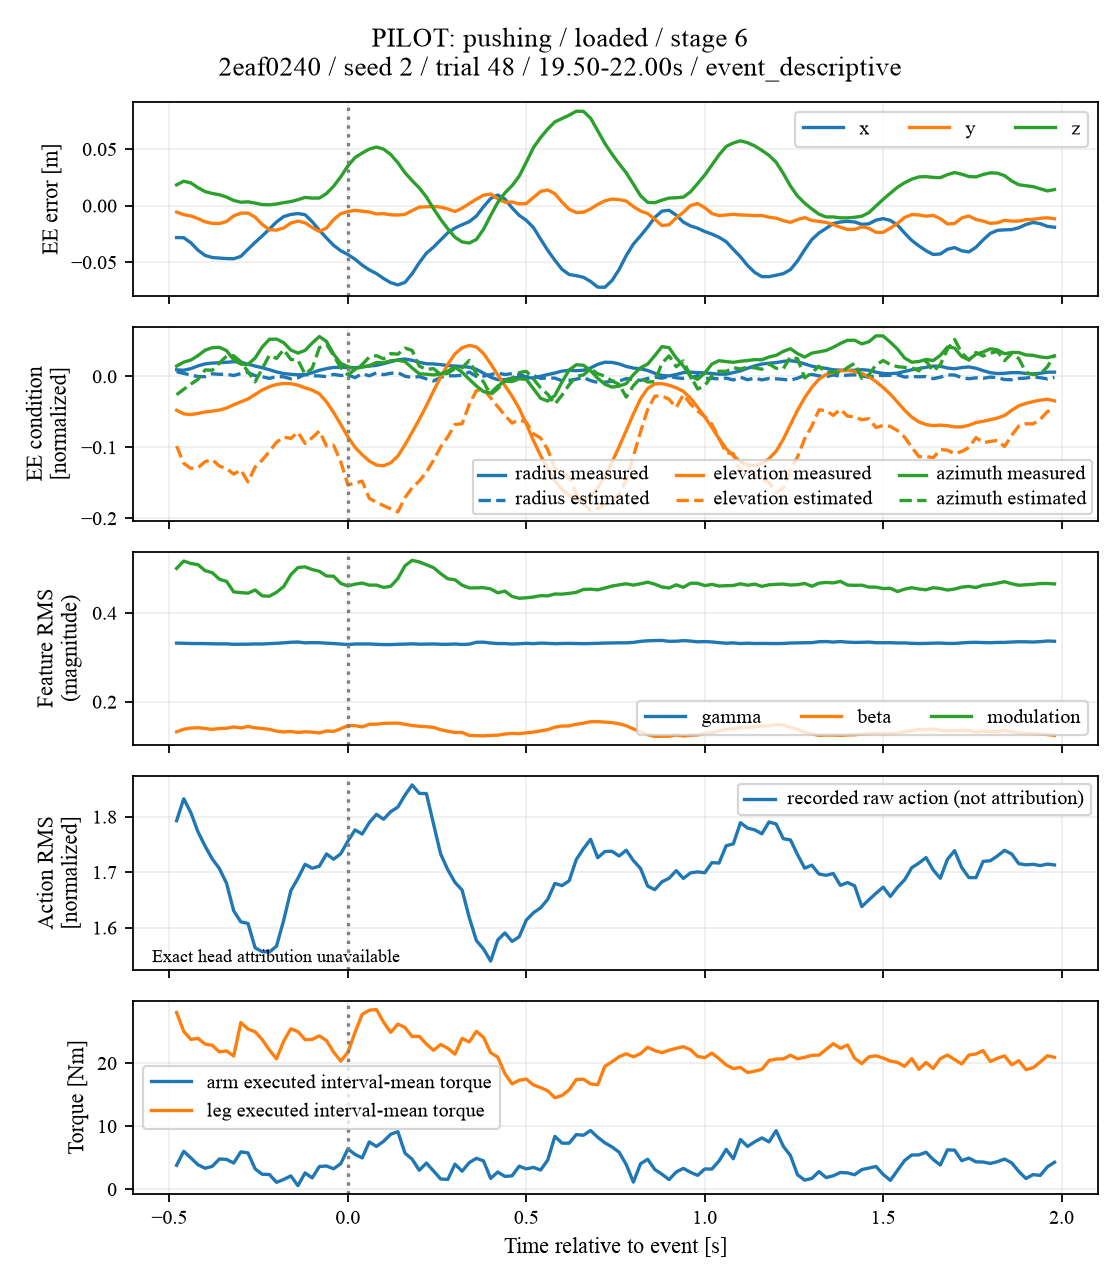

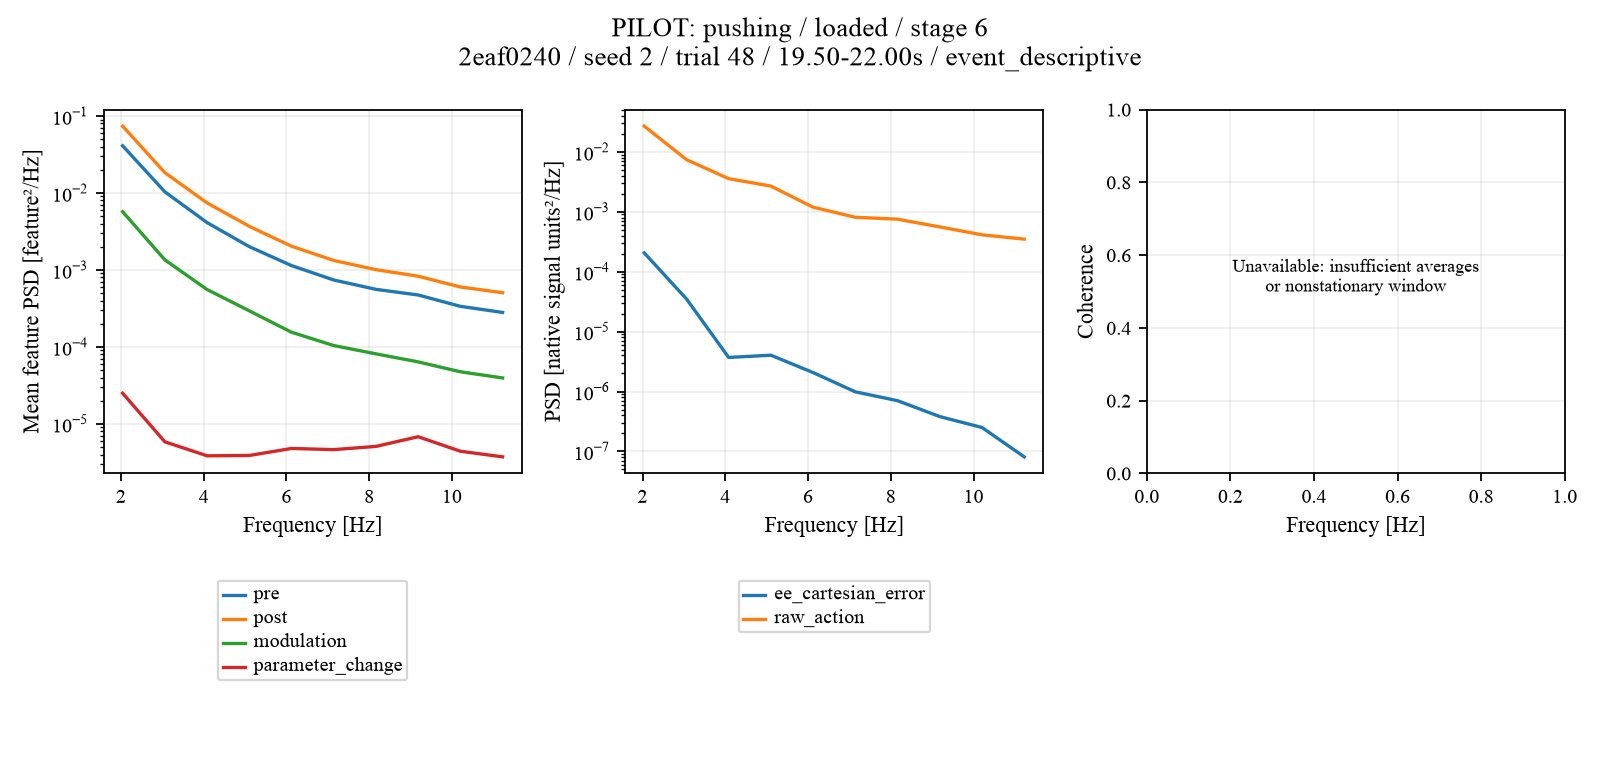

{'profile': 'pushing', 'loading': 'loaded', 'stage': 3, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 2, 'trial_id': 9, 'actual_start': 7.5, 'actual_end': 10.0, 'severity_group': 'high'}


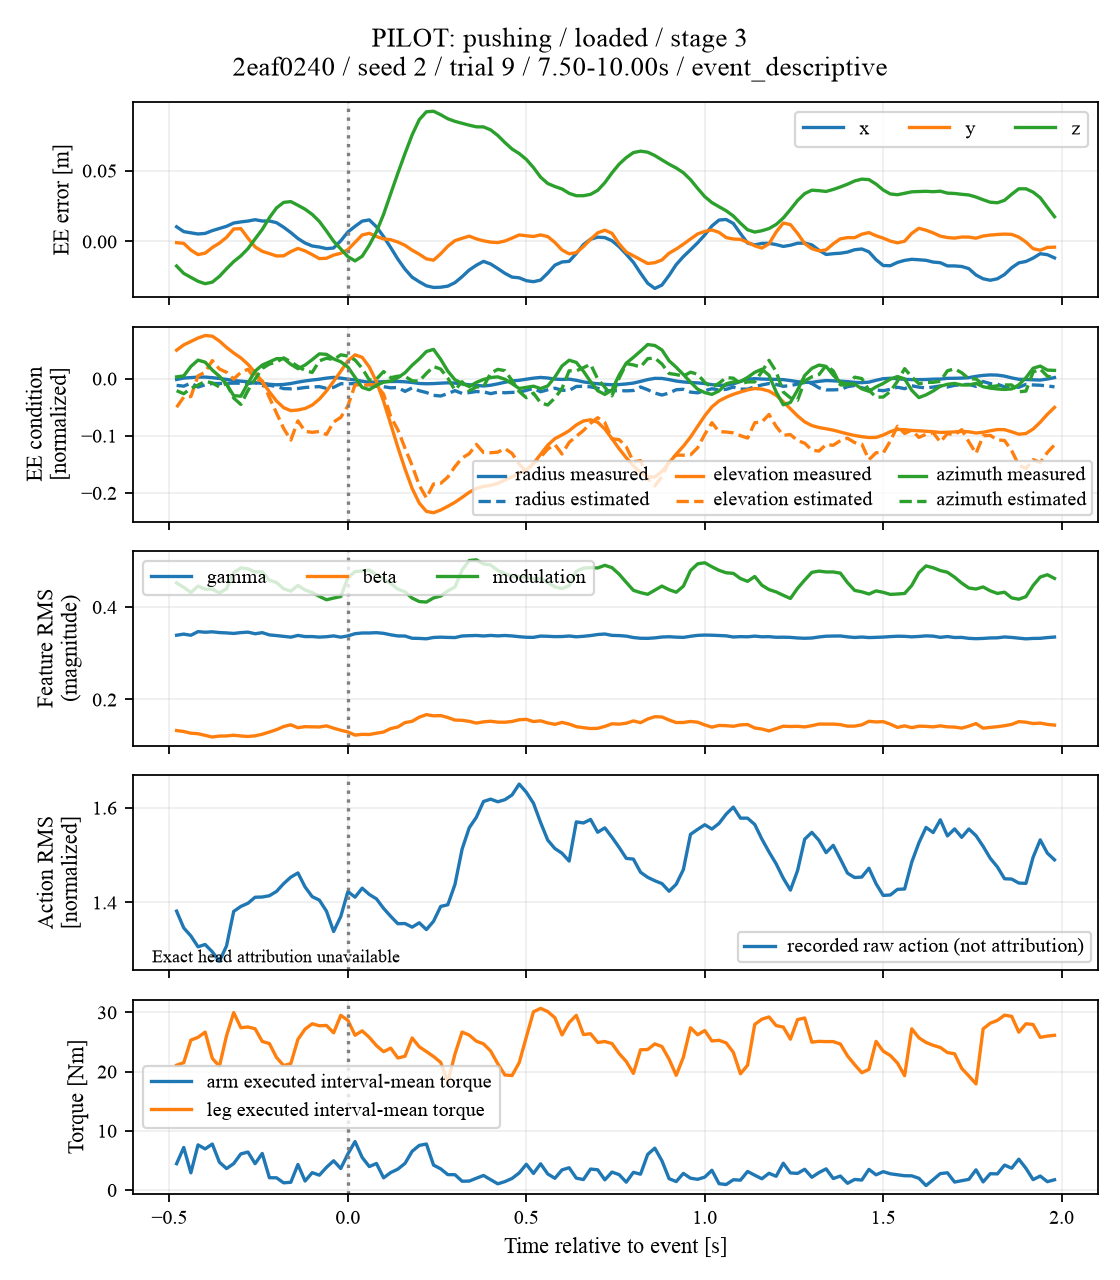

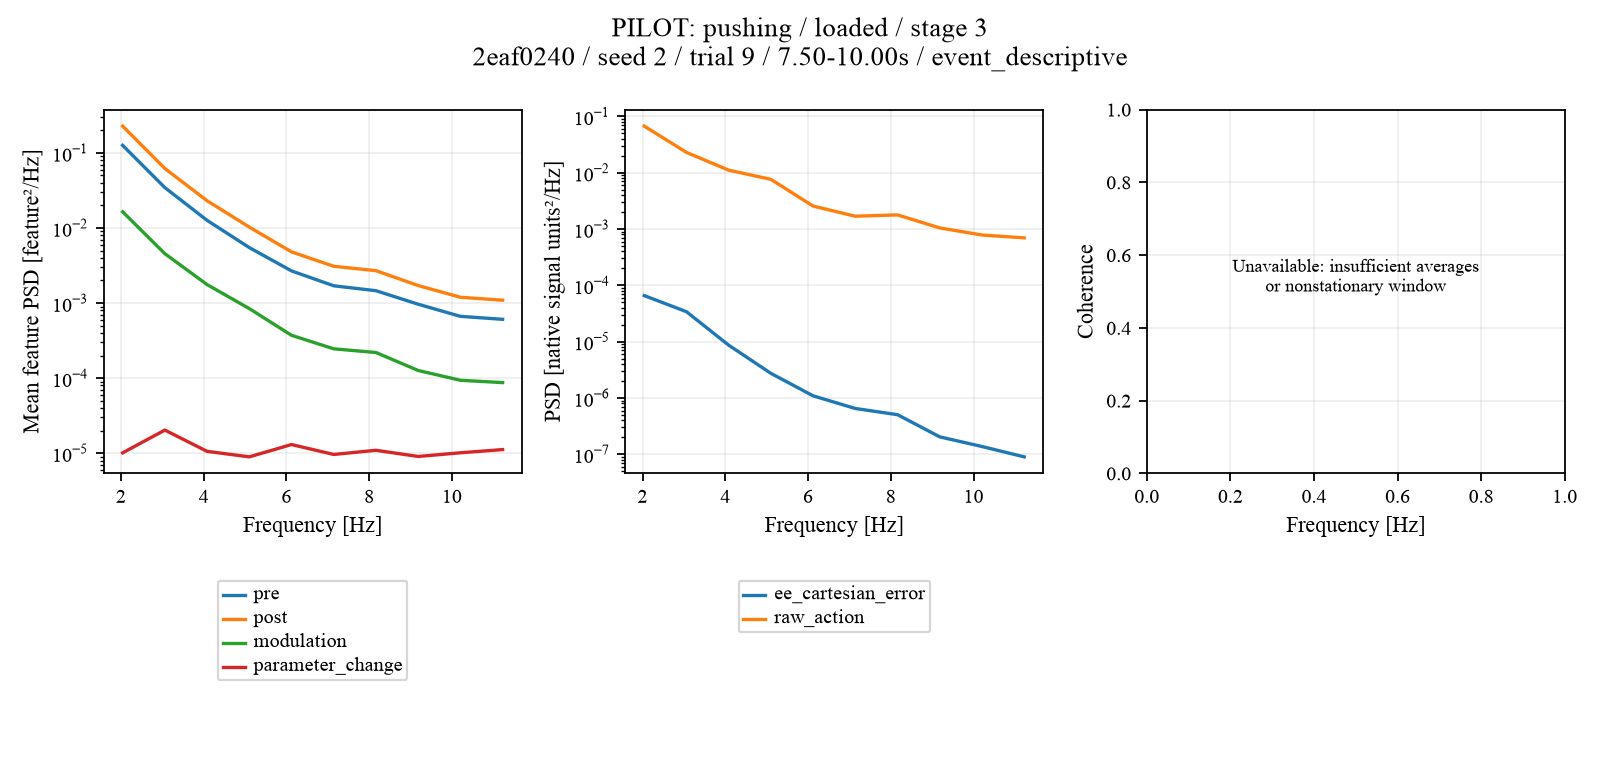

{'profile': 'pulling', 'loading': 'loaded', 'stage': 3, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 0, 'trial_id': 43, 'actual_start': 7.5, 'actual_end': 10.0, 'severity_group': 'high'}


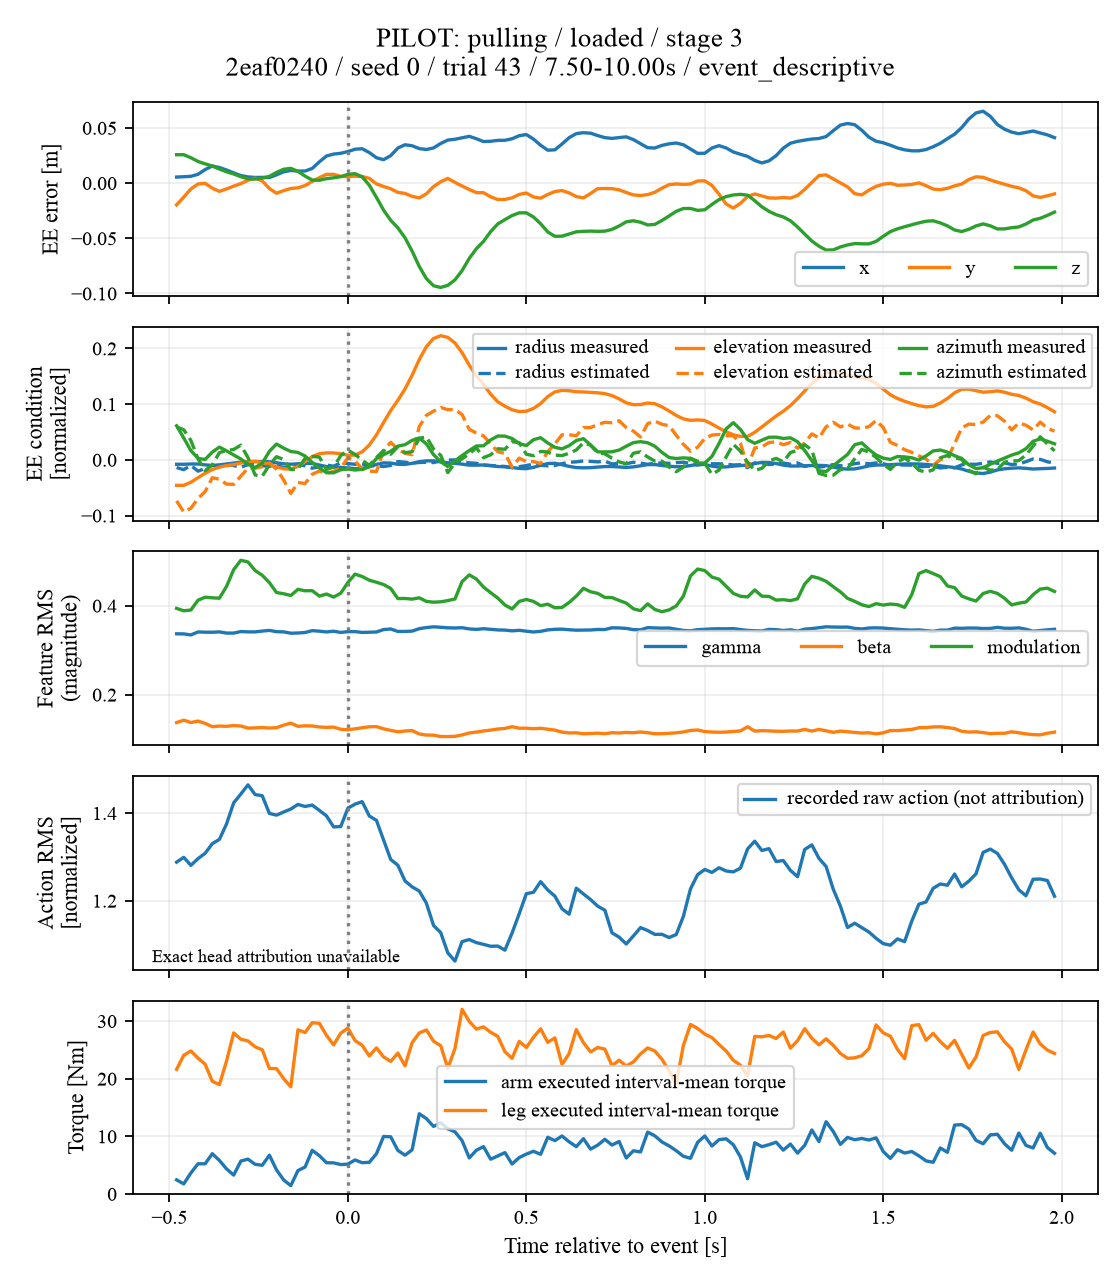

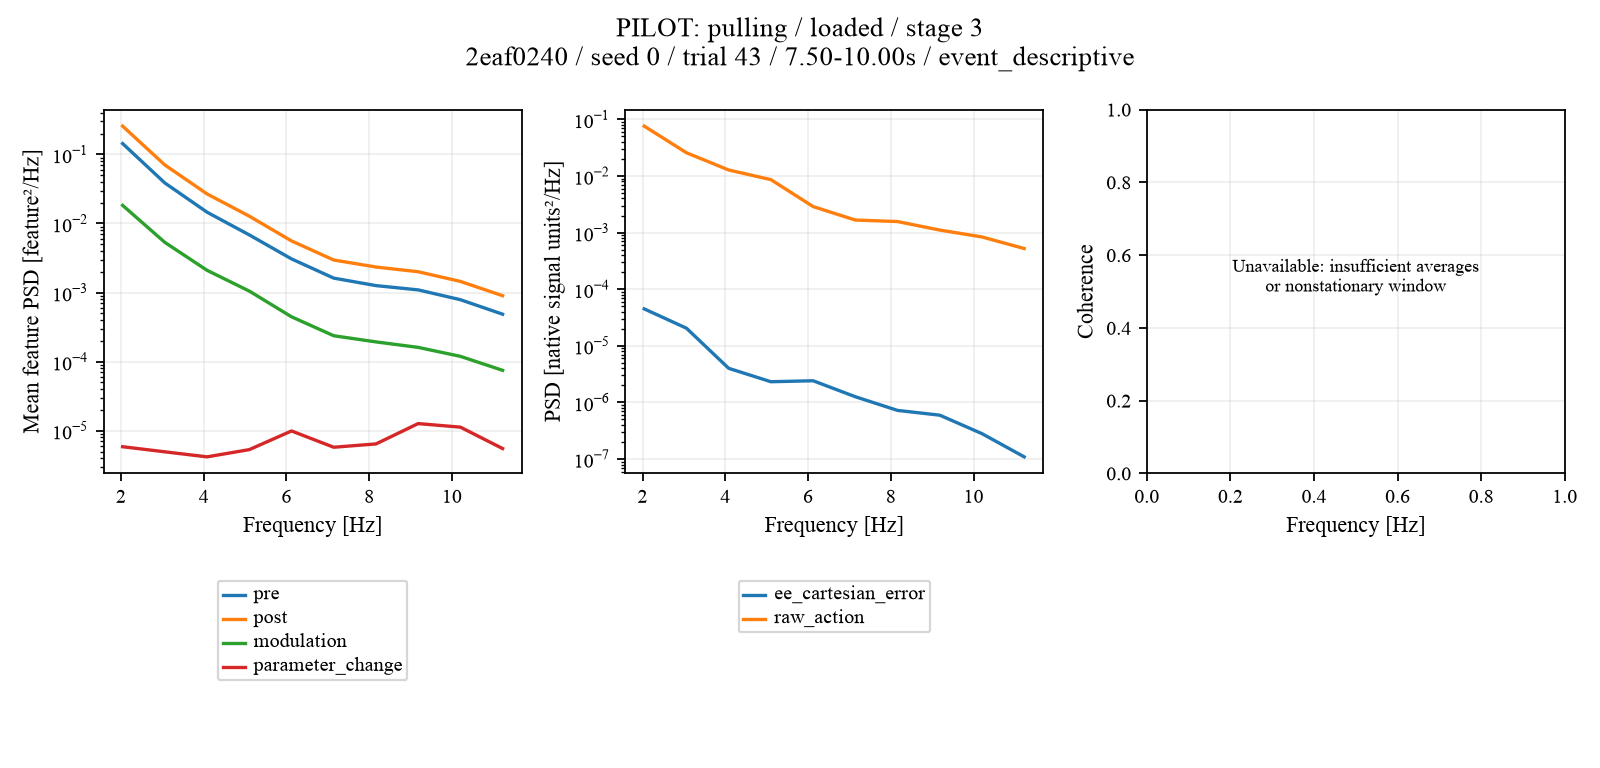

{'profile': 'pushing', 'loading': 'loaded', 'stage': 7, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 2, 'trial_id': 16, 'actual_start': 20.76, 'actual_end': 22.76, 'severity_group': 'high'}


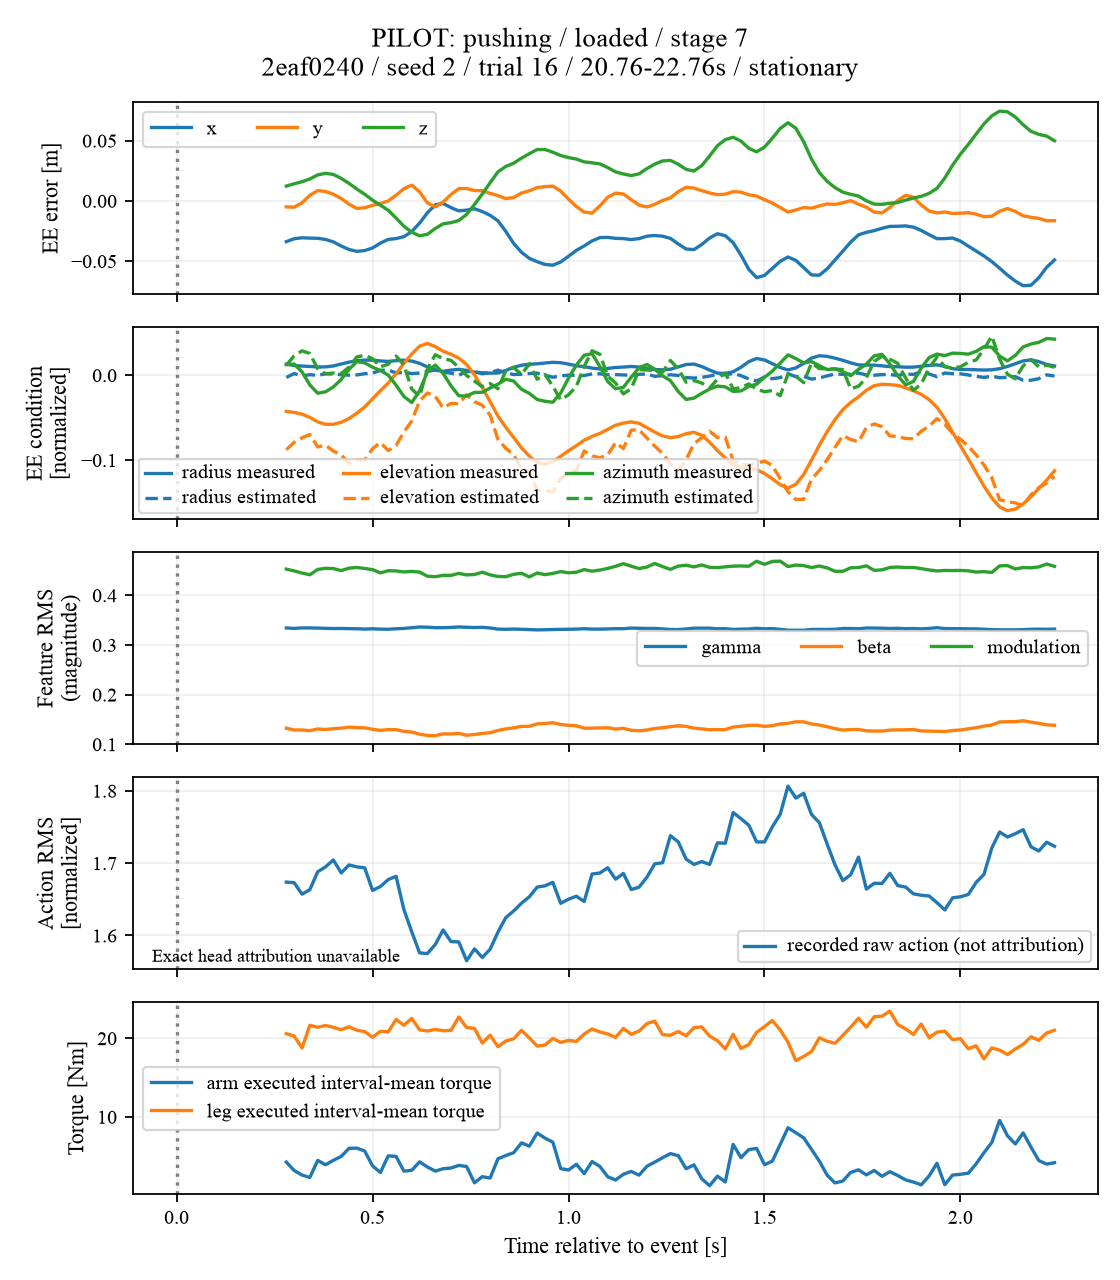

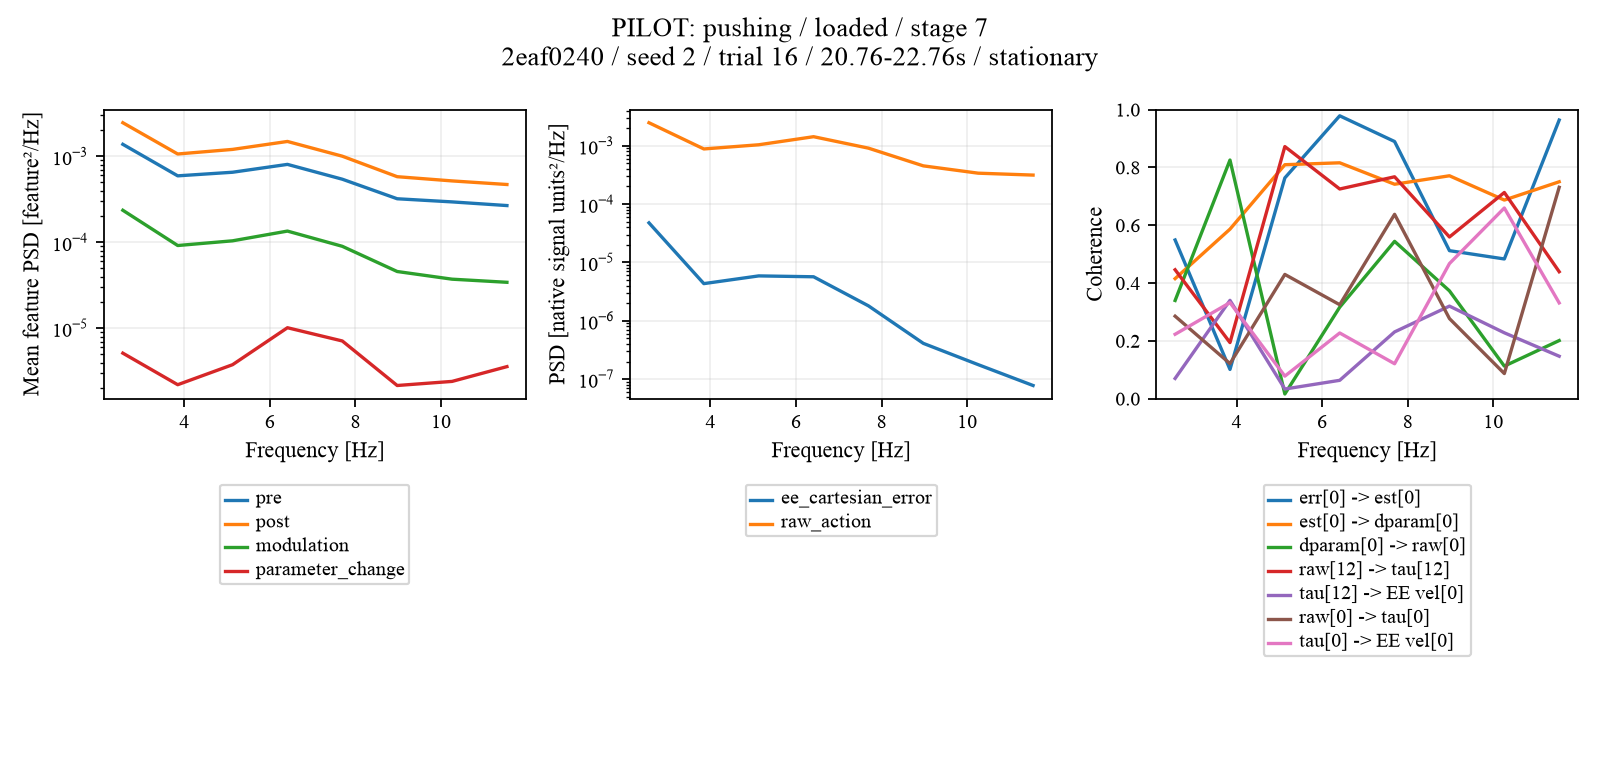

{'profile': 'pulling', 'loading': 'loaded', 'stage': 4, 'checkpoint': '2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c', 'evaluation_seed': 2, 'trial_id': 26, 'actual_start': 13.26, 'actual_end': 17.26, 'severity_group': 'high'}


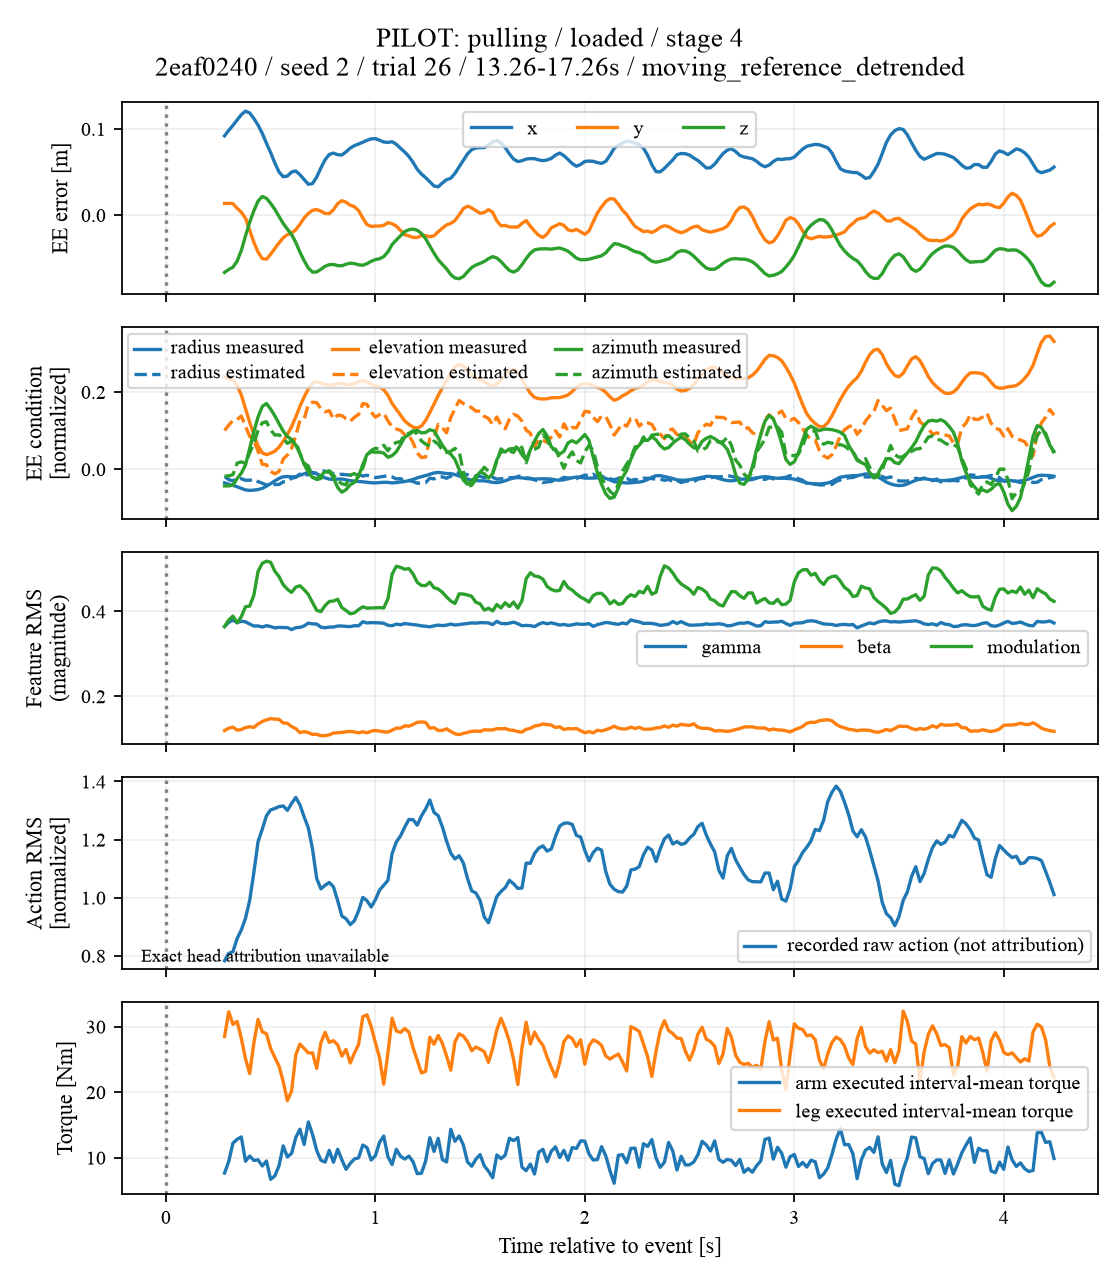

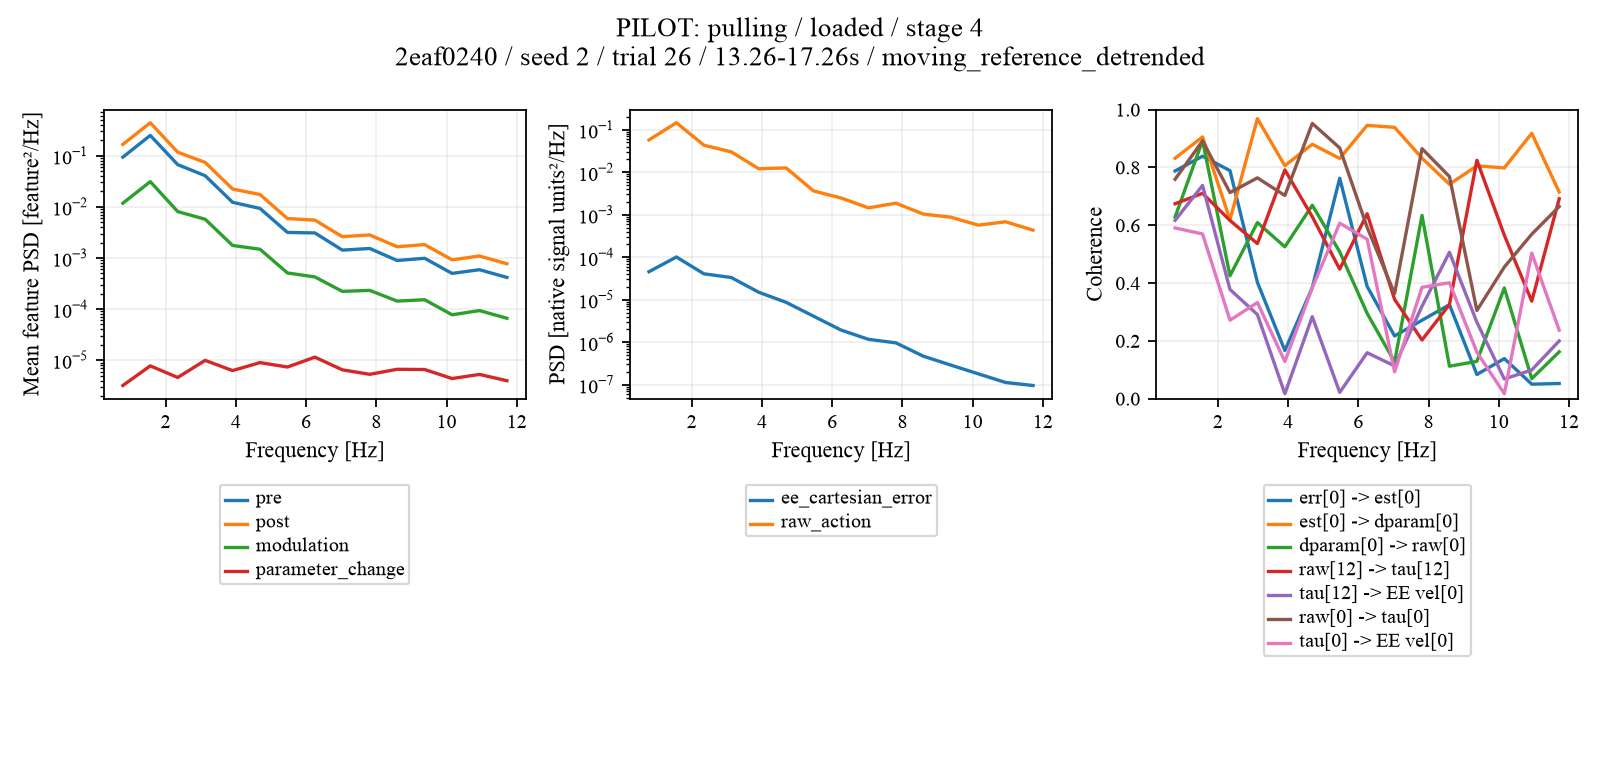

,samples,explained_variance_ratio,coloring,basis,phase_note
2eaf0240106b78e6423f2d6e310318d72b1da561c1af3549eef03e7efc30b94c,1000,"[0.4232125617635737, 0.2166833247997631]",Signed task-x EE error [m],"pooled pre/post, centered, unscaled","Unfiltered Hilbert phase is qualitative, not a..."


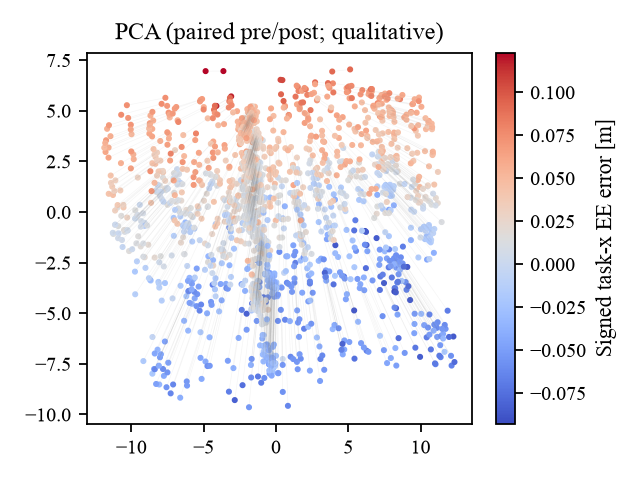

Exports: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp3_film_oscillation


In [5]:
OUT = Path(CONFIG['output_dir'])
display(pd.DataFrame(result['coverage']))
display(pd.DataFrame(result['plot_omitted_categories']))
for selected in result['plot_selection']:
    print({k: selected[k] for k in ['profile', 'loading', 'stage', 'checkpoint', 'evaluation_seed', 'trial_id', 'actual_start', 'actual_end', 'severity_group']})
    for suffix in ('traces', 'spectra'):
        display(Image(filename=str(OUT / f"window-{selected['window_id']:05d}-{suffix}.png")))
display(pd.DataFrame(result['pca']).T)
for path in sorted(OUT.glob('pca-*.png')):
    display(Image(filename=str(path)))
print('Exports:', OUT)


## Dependencies and outputs
CPU: NumPy, SciPy, pandas, matplotlib, Jupyter. Optional PyTorch only deserializes frozen head weights; optional sklearn supplies t-SNE. Isaac Lab and BARD are never initialized.
`summary.json` stores configuration, provenance, units, exclusions, window completeness and checkpoint/seed summaries. `coverage.csv` lists each planned stage and analysis availability; per-window spectral plans remain in JSON. `plot_selection.csv` and `plot_omitted_categories.json` audit selected coverage. CSVs retain per-axis/per-joint statistics, high/low comparisons and frequency/lag links. `window-*.npz` contains timestamped signals and component PSDs, with PDF/PNG figures. A second bounded pass rereads only selected windows for plotting. `COMPLETE` is written last. Use a fresh output directory; no raw recording is modified.